# mini-vLLM, Part 5: N-gram (Prompt-Lookup) Speculation

**What we will build and measure**

[Stage 5](https://github.com/chizkidd/minivllm/blob/main/04_paged_kv_cache.ipynb) ended with a diagnosis:
>_the engine now uses its KV memory well and keeps the batch full, so what is left is the cost of each step: every decode step still reads all the weights to produce one token per sequence._

**Stage 6, speculative decoding with an n-gram draft,** attacks that directly. A decode step is cheap to run on more tokens, so we **guess several tokens ahead, check all the guesses in one forward pass, and keep the ones the model agrees with.** Every kept token is the one the model would have chosen anyway, so the output does not change, only the number of passes does.

This notebook uses the cheapest possible guesser, **prompt lookup**: an n-gram match against the context, with no second model. The checking pass is generic, it works with any source of guesses, and the next stage ([Stage 7](https://github.com/chizkidd/minivllm/blob/main/06_draft_model_speculation.ipynb)) plugs a small **draft model** into the very same verifier and compares the two head to head.

1. **Check a guess in one pass.** Feed the last token and a draft of `k` guessed tokens through the model together, read the model's own choice after each, and accept the longest prefix of the draft that matches. Roll the cache back over the rejected tokens. Prove the output is exactly the plain greedy output.
2. **Guess without a second model.** *Prompt lookup*: find where the last few tokens occurred earlier in the context and propose what followed them. It needs no model and no training, and it works when the output repeats the input.
3. **Measure why checking is cheap.** How does the time of a forward pass grow when every sequence feeds more tokens, and at which batch size does it stop being cheap?
4. **Measure when guessing works.** How often is the draft right, on text that copies its input, on repetitive code, and on open-ended writing?
5. **Measure the speedup**, and compare it with what the two earlier measurements predict.
6. **Project it to batching.** What happens to the gain when many sequences share each pass?

**How to use this notebook.** Same shape as the earlier parts: *Goal, Concept, Code, Result, Takeaway*, with a prediction before every benchmark. The takeaways are written as "how to read the result" because the numbers come from your run.

| # | Section | What we learn | Approx. runtime on a Kaggle T4 |
| --- | --- | --- | --- |
| 1 | Setup | Reproducible environment | seconds |
| 2 | The code | Prompt lookup, the checking pass, the cache rollback | seconds |
| 3 | Load model and correctness gates | Speculative decoding equals plain greedy decoding | about 1 min |
| 4 | A. Why checking is cheap | Forward pass time vs tokens fed per sequence | about 2 min |
| 5 | B. When guessing works | Acceptance and tokens per pass by workload and draft length | about 4 min |
| 6 | C. The speedup | Measured vs predicted, and the ceiling | about 2 min |
| 7 | D. Under batching | A projection from sections A and B | seconds |
| 8 | Save results | JSON and figure inventory | seconds |
| 9 | Publish (optional) | Push results (and code, if newest) to GitHub | seconds |
| 10 | Summary | Findings and what comes next | seconds |

**Kaggle setup:** Accelerator = GPU T4 x2 (we use only the first GPU), Internet = On. Run top to bottom and restart the kernel before the final run. Set `QUICK = True` in the setup cell for a run of about 4 minutes instead of about 10.

**Self-contained.** Like the earlier parts, the `%%writefile` cells write the whole `minivllm/` and `bench/` packages and the notebook imports them. Files that did not change since Part 4 are repeated verbatim. `minivllm/speculative.py` and `bench/texts.py` are new, `minivllm/model.py` gained `all_logits` and accepts several tokens on a non-empty cache when given a mask, `minivllm/kv_cache.py` gained `KVCache.truncate`, and `bench/metrics.py` gained `verify_cost` and `sweep_speculative`.

---
## 1. Setup

**Goal:** one imports cell, one environment record.

- `CUDA_VISIBLE_DEVICES=0` is set *before* importing torch, so "we only use one GPU" is enforced rather than assumed.
- `ENV` records GPU, torch, transformers and python versions, saved with the results.
- `QUICK = True` shrinks the sweeps (fewer draft lengths, batch sizes and tokens) for a fast pass.
- After editing a `%%writefile` cell, re-run it and then restart the kernel (or reload the module), because modules that were already imported keep their old code.

In [1]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle T4 x2: use one GPU only

import gc, platform

import numpy as np
import pandas as pd
import torch, transformers

for d in ("minivllm", "bench", "results"):
    os.makedirs(d, exist_ok=True)
for pkg in ("minivllm", "bench"):
    open(f"{pkg}/__init__.py", "a").close()

assert torch.cuda.is_available(), "Turn on a GPU accelerator in Kaggle settings"

QUICK = False   # True: fewer draft lengths, batch sizes and tokens (about 4 minutes instead of about 10)
SEED = 0

ENV = {
    "gpu": torch.cuda.get_device_name(0),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "python": platform.python_version(),
}
print(ENV)

{'gpu': 'Tesla T4', 'torch': '2.11.0+cu128', 'transformers': '5.16.1', 'python': '3.13.15'}


---
## 2. The code

Two files hold the idea: `minivllm/speculative.py` (the draft and the loop) and the small changes to `minivllm/model.py` and `minivllm/kv_cache.py` that let one pass check several tokens. Read them in this order. The files that did not change follow at the end of this section.

### 2.1 Checking several tokens in one pass (`minivllm/model.py`, `minivllm/kv_cache.py`)

**Concept.** A normal decode step feeds one token, the last one generated, and reads the logits after it. To check a draft `[d1, d2, d3]` we feed `[last, d1, d2, d3]` **together** on top of the cache. Position `j` of the output holds the model's own choice for the token that comes *after* input `j`:

```
fed:      last    d1      d2      d3
choice:   c0      c1      c2      c3        c_j = the model's greedy token after input j

draft is right at d1 if c0 == d1, at d2 if c1 == d2, at d3 if c2 == d3.
If d1 and d2 are right and d3 is wrong:   accept d1, d2, and take c2 as a bonus  ->  3 tokens from one pass
If d1 is wrong:                           take c0                                ->  1 token, an ordinary step
```

Every token we keep is one of the model's own choices, computed from the true prefix, so the result is the same as plain greedy decoding. The pass costs about the same as a one-token step, and it can yield up to `k + 1` tokens.

Two small changes make this possible:

- **`model.forward(..., all_logits=True)`** returns the logits of *every* fed position, `[B, T, vocab]`, instead of only the last one. The default is unchanged.
- **Several tokens on a non-empty cache** used to be refused, because the default causal mask assumes an empty cache. The checking pass passes an explicit mask instead: input `j` sits at position `n + j` and may attend to every key up to and including its own. Positions are consecutive from the cache length, as before.
- **`KVCache.truncate(length)`** rolls the cache back. The pass wrote the keys of all fed tokens, including the rejected drafts. We keep the first `a + 1` (the last token and the `a` accepted drafts) and forget the rest. The stale keys stay in memory but are never read, and the next write overwrites them.

### 2.2 Guessing with prompt lookup, and the loop (`minivllm/speculative.py`)

**Concept.** `PromptLookup` is a draft that needs no model. It takes the last `n` tokens of the context (longest `n` first, up to `ngram_max`), looks for the **most recent earlier occurrence** of the same `n` tokens, and proposes the tokens that followed them. If the text is being copied or repeats a pattern, the next tokens are likely to repeat too. If nothing matches, it proposes nothing and the pass is an ordinary step.

`generate_speculative` is the loop: prefill, then each iteration draft up to `k` tokens, run one checking pass, accept the longest agreeing prefix plus the bonus token, and truncate the cache. It never produces more than `max_new` tokens, and `rollback=False` exists only for the negative control in section 3.

A draft only helps if (a) it is **often right** and (b) checking it is **cheap**. Section 4 measures (b), section 5 measures (a).

In [2]:
%%writefile minivllm/model.py
import torch
import torch.nn.functional as F

def rms_norm(x, weight, eps):
    xf = x.float()
    xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + eps)
    return weight * xf.to(x.dtype)

def rotate_half(x):
    h = x.shape[-1] // 2
    return torch.cat((-x[..., h:], x[..., :h]), dim=-1)

def apply_rope(x, cos, sin):
    return x * cos + rotate_half(x) * sin

class MiniQwen:
    def __init__(self, hf_model, max_pos=2048):
        cfg = hf_model.config
        self.n_layers = cfg.num_hidden_layers
        self.n_heads = cfg.num_attention_heads
        self.n_kv = cfg.num_key_value_heads
        self.hd = getattr(cfg, "head_dim", None) or cfg.hidden_size // self.n_heads
        self.n_rep = self.n_heads // self.n_kv
        self.eps = cfg.rms_norm_eps

        m = hf_model.model
        self.embed = m.embed_tokens.weight
        self.norm_w = m.norm.weight
        self.lm_head = hf_model.lm_head.weight
        self.device, self.dtype = self.embed.device, self.embed.dtype
        self.layers = []
        for l in m.layers:
            a, mlp = l.self_attn, l.mlp
            self.layers.append(dict(
                ln1=l.input_layernorm.weight, ln2=l.post_attention_layernorm.weight,
                q_w=a.q_proj.weight, q_b=a.q_proj.bias,
                k_w=a.k_proj.weight, k_b=a.k_proj.bias,
                v_w=a.v_proj.weight, v_b=a.v_proj.bias,
                o_w=a.o_proj.weight,
                gate=mlp.gate_proj.weight, up=mlp.up_proj.weight, down=mlp.down_proj.weight,
            ))

        theta = getattr(cfg, "rope_theta", None)
        if theta is None:
            theta = cfg.rope_parameters["rope_theta"]
        inv = 1.0 / (theta ** (torch.arange(0, self.hd, 2, device=self.device).float() / self.hd))
        t = torch.arange(max_pos, device=self.device).float()
        emb = torch.cat([torch.outer(t, inv)] * 2, dim=-1)
        self.cos, self.sin = emb.cos().to(self.dtype), emb.sin().to(self.dtype)

    @torch.no_grad()
    def forward(self, ids, cache=None, positions=None, attn_mask=None, all_logits=False):
        """
        ids: [B, T]. Returns logits for the LAST position only: [B, vocab].
        Batching of sequences with different lengths (Stage 3) adds two optional inputs:
          positions: [B, T] RoPE position of every token (default: consecutive from the cache length).
          attn_mask: bool [B, 1, T, L], True = this query may attend to this key, where L is the
                     number of keys after the cache update (default: causal, no padding).
        Speculative decoding (Stage 6) adds all_logits: return the logits of every position, [B, T, vocab], so
        one pass can check several drafted tokens. Feeding T > 1 tokens on top of a non-empty cache (the checking
        pass) needs an explicit attn_mask, because the default causal mask assumes an empty cache.
        """
        B, T = ids.shape
        pos0 = cache.length if cache is not None else 0
        assert not (cache is not None and T > 1 and pos0 > 0 and attn_mask is None), \
            "several tokens on a non-empty cache need an explicit attn_mask"
        if positions is None:
            assert pos0 + T <= self.cos.shape[0], "sequence longer than RoPE table"
            cos = self.cos[pos0:pos0 + T][None, None]
            sin = self.sin[pos0:pos0 + T][None, None]
        else:
            cos = self.cos[positions][:, None]   # [B, 1, T, head_dim]
            sin = self.sin[positions][:, None]

        x = F.embedding(ids, self.embed)
        for i, L in enumerate(self.layers):
            h = rms_norm(x, L["ln1"], self.eps)
            q = F.linear(h, L["q_w"], L["q_b"]).view(B, T, self.n_heads, self.hd).transpose(1, 2)
            k = F.linear(h, L["k_w"], L["k_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            v = F.linear(h, L["v_w"], L["v_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
            if cache is not None:
                k, v = cache.update(i, k, v)
            # Expand KV heads to match query heads (GQA). Wasteful, a known optimization target.
            k = k.repeat_interleave(self.n_rep, dim=1)
            v = v.repeat_interleave(self.n_rep, dim=1)
            a = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                               is_causal=(attn_mask is None and T > 1))
            a = a.transpose(1, 2).reshape(B, T, -1)
            x = x + F.linear(a, L["o_w"])
            h = rms_norm(x, L["ln2"], self.eps)
            x = x + F.linear(F.silu(F.linear(h, L["gate"])) * F.linear(h, L["up"]), L["down"])
        if cache is not None:
            cache.advance(T)
        x = rms_norm(x if all_logits else x[:, -1], self.norm_w, self.eps)
        return F.linear(x, self.lm_head)

Writing minivllm/model.py


### 2.3 Unchanged from Part 4

`minivllm/batching.py`, `minivllm/block_allocator.py`, `minivllm/scheduler.py` (static, continuous and paged batching), `minivllm/engine.py` (`generate_cached`, the plain greedy baseline) and `minivllm/utils.py`. `KVCache` gained only `truncate`; `SlotCache` and `PagedCache` are untouched.

In [3]:
%%writefile minivllm/batching.py
import torch

def left_pad(seqs, pad_id, device, pad_to=None):
    """
    Stack variable-length token lists into one [B, T] tensor, padding on the LEFT so that the
    last column is a real token for every sequence (generation reads the last position).
    Returns (ids [B, T], lens [B]) where lens are the real prompt lengths. `pad_to` forces a
    longer T than the longest prompt (e.g. to round up to a multiple of 8). 
    
    If you use `pad_to`, build the matching `Layout(..., T=ids.shape[1])` too: Layout assumes 
    the longest prompt otherwise, and its positions and masks would not fit the tensor.
    """
    lens = [len(s) for s in seqs]
    T = max(lens + [pad_to or 0])
    ids = torch.full((len(seqs), T), pad_id, dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, T - len(s):] = torch.as_tensor(s, dtype=torch.long)
    return ids.to(device), torch.tensor(lens, device=device)

class Layout:
    """
    Positions and attention masks for one wave of left-padded sequences.
    
      column:   0 1 2 3 4 5 | 6 7 8 ...      T = longest prompt, then generated tokens follow
      seq A:    . . A A A A | g g g          (. = padding, A = prompt token, g = generated)
      seq B:    . B B B B B | g g g
    
    Every sequence shares the same cache columns, so the cache stays a single rectangle. Padding
    columns are never attended to, and RoPE positions count only real tokens (A starts at 0).
    """                                                                         
    def __init__(self, lens, max_new, device, T=None):
        self.lens = lens.to(device)                         # [B] real prompt lengths
        self.T = T or int(self.lens.max())                  # padded prompt length (columns)
        self.device = device
        self.pad = self.T - self.lens                       # [B] padding columns per sequence
        cols = torch.arange(self.T + max_new, device=device)
        self.key_real = cols[None, :] >= self.pad[:, None]  # [B, T + max_new]: True on real tokens

    def prefill(self):
        """positions [B, T] and mask [B, 1, T, T] for the prompt pass."""
        T, dev = self.T, self.device
        cols = torch.arange(T, device=dev)
        positions = (cols[None, :] - self.pad[:, None]).clamp(min=0)
        causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=dev))
        mask = causal[None] & self.key_real[:, None, :T]
        # A padding query would otherwise have no key to attend to. A fully masked row makes the
        # softmax NaN, and 0 * NaN is NaN, so it would poison real tokens. Let it see itself.
        mask = mask | torch.eye(T, dtype=torch.bool, device=dev)[None]
        return positions, mask[:, None]

    def decode(self, j):
        """
        positions [B, 1] and mask [B, 1, 1, L] for the step that consumes generated token j
        (j = 1 is the token the prompt pass produced). It sits in cache column T + j - 1.
        """
        positions = (self.lens + (j - 1))[:, None]
        mask = self.key_real[:, None, None, :self.T + j]
        return positions, mask

Writing minivllm/batching.py


In [4]:
%%writefile minivllm/block_allocator.py
from collections import deque


class BlockAllocator:
    """
    A pool of `num_blocks` fixed-size KV blocks, handed out and taken back by id.

    The allocator knows nothing about tensors or tokens: it only tracks which block ids are free. A sequence
    that needs `n` blocks gets a list of `n` ids (its block table) and gives them back when it finishes, so
    memory freed by one request is immediately usable by the next, whatever their lengths.

    Free ids are kept in a FIFO queue. That is not required for correctness, but it recycles blocks in
    release order, so after some churn a sequence's blocks are scattered over the pool instead of forming one
    contiguous run, which is exactly the situation a block table exists to handle.
    """
    def __init__(self, num_blocks):
        assert num_blocks > 0
        self.num_blocks = num_blocks
        self._free = deque(range(num_blocks))
        self._in_use = [False] * num_blocks

    @property
    def num_free(self):
        return len(self._free)

    @property
    def num_used(self):
        return self.num_blocks - len(self._free)

    def can_allocate(self, n):
        return n <= len(self._free)

    def allocate(self, n):
        """Take `n` free blocks. Returns their ids; raises if the pool cannot supply them."""
        if not self.can_allocate(n):
            raise MemoryError(f"need {n} blocks, only {len(self._free)} free")
        ids = [self._free.popleft() for _ in range(n)]
        for b in ids:
            self._in_use[b] = True
        return ids

    def free(self, ids):
        """Give blocks back. Freeing a block that is not in use is a bug (a double free), so it raises."""
        for b in ids:
            if not self._in_use[b]:
                raise ValueError(f"block {b} is not in use")
            self._in_use[b] = False
            self._free.append(b)

Writing minivllm/block_allocator.py


In [5]:
%%writefile minivllm/kv_cache.py
import torch
import torch.nn.functional as F

from .block_allocator import BlockAllocator

class KVCache:
    """
    Contiguous, preallocated cache for a batch of sequences.
    Each tensor has shape [n_layers, batch, n_kv_heads, max_len, head_dim].
    """
    def __init__(self, n_layers, batch, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, batch, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.length = 0
        self.max_len = max_len

    def update(self, layer, k, v):
        """k, v: [batch, n_kv_heads, T, head_dim]. Returns everything cached so far."""
        T = k.shape[2]
        end = self.length + T
        assert end <= self.max_len, "KV cache overflow"
        self.k[layer, :, :, self.length:end] = k
        self.v[layer, :, :, self.length:end] = v
        return self.k[layer, :, :, :end], self.v[layer, :, :, :end]

    def advance(self, T):
        """Called once per forward pass, after all layers have written."""
        self.length += T

    def truncate(self, length):
        """Forget everything after the first `length` tokens (Stage 6: drop the rejected draft tokens).
        The old keys stay in memory but are never read, and the next write overwrites them."""
        assert 0 <= length <= self.length, "can only truncate to a shorter length"
        self.length = length

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()

    @staticmethod
    def bytes_per_token(n_layers, n_kv_heads, head_dim, dtype_bytes=2):
        return 2 * n_layers * n_kv_heads * head_dim * dtype_bytes


class SlotCache:
    """
    A fixed pool of `slots` sequence slots, each with room for `max_len` tokens, for continuous batching.
    Shape [n_layers, slots, n_kv_heads, max_len, head_dim], like KVCache, but every slot has its OWN length
    (`lens`). A finished sequence frees its slot at once and a waiting request is prefilled into it, while
    the other slots keep decoding. Each slot is still one contiguous worst-case rectangle (Stage 5 replaces
    that with blocks).

    model.forward only needs `length`, `update` and `advance`, so two small views plug the pool into it:
      prefill_view(slot): one new prompt (batch 1, no padding) written into one free slot.
      decode_view():      one token for EVERY slot at its own column. Slots that are free decode a dummy
                          token that is masked and overwritten later, which keeps the batch shape fixed.
    """
    def __init__(self, n_layers, slots, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, slots, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.slots, self.max_len, self.device = slots, max_len, device
        self.lens = [0] * slots     # tokens stored per slot; plain ints, so reading them never syncs the GPU

    def prefill_view(self, slot):
        return _PrefillView(self, slot)

    def decode_view(self):
        return _DecodeView(self)

    def free(self, slot):
        self.lens[slot] = 0

    @property
    def used_tokens(self):
        return sum(self.lens)

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()


class _PrefillView:
    length = 0   # forward() reads this only to start positions at 0, and a prefill starts from an empty slot

    def __init__(self, cache, slot):
        assert cache.lens[slot] == 0, "slot is not free"
        self.c, self.slot = cache, slot

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]."""
        T = k.shape[2]
        assert T <= self.c.max_len, "KV slot overflow"
        self.c.k[layer, self.slot, :, :T] = k[0]
        self.c.v[layer, self.slot, :, :T] = v[0]
        return self.c.k[layer, self.slot:self.slot + 1, :, :T], self.c.v[layer, self.slot:self.slot + 1, :, :T]

    def advance(self, T):
        self.c.lens[self.slot] = T


class _DecodeView:
    length = 0   # positions are passed in explicitly, so forward() never needs the shared length

    def __init__(self, cache):
        self.c = cache
        self.rows = torch.arange(cache.slots, device=cache.device)
        self.cols = torch.tensor(cache.lens, device=cache.device)   # the column each slot writes its new token to
        self.end = max(cache.lens) + 1                               # columns that can matter this step
        assert self.end <= cache.max_len, "KV slot overflow"

    def update(self, layer, k, v):
        """k, v: [slots, n_kv_heads, 1, head_dim]. Returns the first `end` columns of every slot."""
        self.c.k[layer, self.rows, :, self.cols] = k[:, :, 0]
        self.c.v[layer, self.rows, :, self.cols] = v[:, :, 0]
        return self.c.k[layer, :, :, :self.end], self.c.v[layer, :, :, :self.end]

    def advance(self, T):
        pass     # the scheduler advances only the slots that are actually running


class PagedCache:
    """
    A KV cache made of fixed-size blocks drawn from one shared pool (Stage 5).
    Each tensor has shape [n_layers, num_blocks, n_kv_heads, block_size, head_dim]. A sequence does not own a
    rectangle: it owns a list of block ids (its block table) and a length, and token t of the sequence lives in
    block table[t // block_size] at offset t % block_size. Blocks are handed out by a BlockAllocator when a
    sequence is added and returned the moment it is freed, so a request holds memory for the tokens it needs,
    not for the longest request the server might ever see.

    Sequences are named by any hashable id (we use the request id). `add(seq, tokens)` reserves enough blocks
    for the whole request, `tokens` = prompt + generated tokens that will be stored, so a running sequence can
    never run out of blocks half way (Stage 5 keeps admission simple; reserving lazily needs preemption,
    which is exercise 1).

    model.forward only needs `length`, `update` and `advance`, so two views plug the pool into it, as for SlotCache:
      prefill_view(seq):  one new prompt (batch 1, no padding) written into the sequence's blocks.
      decode_view(seqs):  one token for each listed sequence, each written at its own position. The keys and
                          values of those sequences are gathered through their block tables into one dense
                          tensor, then ordinary attention runs on it.
    """
    def __init__(self, n_layers, num_blocks, block_size, n_kv_heads, head_dim, device, dtype):
        shape = (n_layers, num_blocks, n_kv_heads, block_size, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.num_blocks, self.block_size, self.device = num_blocks, block_size, device
        self.n_kv_heads, self.head_dim = n_kv_heads, head_dim
        self.allocator = BlockAllocator(num_blocks)
        self.tables = {}     # seq -> list of block ids
        self.lens = {}       # seq -> tokens stored (plain ints, so reading them never syncs the GPU)
        self.cap = {}        # seq -> tokens reserved for it

    def blocks_for(self, tokens):
        return -(-tokens // self.block_size)

    def can_admit(self, tokens):
        return self.allocator.can_allocate(self.blocks_for(tokens))

    def add(self, seq, tokens):
        """Reserve blocks for a sequence that will store up to `tokens` tokens."""
        assert seq not in self.tables, "sequence already in the cache"
        self.tables[seq] = self.allocator.allocate(self.blocks_for(tokens))
        self.lens[seq], self.cap[seq] = 0, tokens

    def free(self, seq):
        """Give the sequence's blocks back to the pool. Their contents are not erased, only forgotten."""
        self.allocator.free(self.tables.pop(seq))
        del self.lens[seq], self.cap[seq]

    def prefill_view(self, seq):
        return _PagedPrefillView(self, seq)

    def decode_view(self, seqs):
        return _PagedDecodeView(self, list(seqs))

    @property
    def used_tokens(self):
        """Tokens actually stored."""
        return sum(self.lens.values())

    @property
    def reserved_tokens(self):
        """Tokens the running sequences will have stored when they finish."""
        return sum(self.cap.values())

    @property
    def allocated_tokens(self):
        """Token capacity of the blocks handed out (reserved tokens rounded up to whole blocks)."""
        return self.allocator.num_used * self.block_size

    @property
    def bytes_per_block(self):
        return 2 * self.k.shape[0] * self.k[0, 0].numel() * self.k.element_size()

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()


class _PagedPrefillView:
    length = 0   # forward() reads this only to start positions at 0, and a prefill starts from an empty sequence

    def __init__(self, cache, seq):
        assert cache.lens[seq] == 0, "sequence already has tokens"
        self.c, self.seq = cache, seq

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]. Writes them block by block and returns them unchanged."""
        c, T = self.c, k.shape[2]
        assert T <= c.cap[self.seq], "KV reservation overflow"
        nb = c.blocks_for(T)
        blocks = torch.tensor(c.tables[self.seq][:nb], device=c.device)
        pad = nb * c.block_size - T
        for cache_t, x in ((c.k, k), (c.v, v)):
            # [n_kv, T, hd] -> pad the last block with zeros -> [nb, n_kv, block_size, hd]
            x = F.pad(x[0], (0, 0, 0, pad)).view(c.n_kv_heads, nb, c.block_size, c.head_dim).transpose(0, 1)
            cache_t[layer, blocks] = x
        return k, v   # a prefill attends to the prompt it just computed, so there is nothing to gather

    def advance(self, T):
        self.c.lens[self.seq] = T


class _PagedDecodeView:
    length = 0   # positions are passed in explicitly, so forward() never needs the shared length

    def __init__(self, cache, seqs):
        self.c = cache
        bs = cache.block_size
        lens = [cache.lens[s] for s in seqs]
        assert all(l < cache.cap[s] for s, l in zip(seqs, lens)), "KV reservation overflow"
        self.end = max(lens) + 1                      # columns that can matter this step
        nb = cache.blocks_for(self.end)
        # Block table of the batch, [n, nb]. A sequence with fewer blocks is padded with block 0: those columns
        # lie beyond its position, so the attention mask hides whatever they hold.
        table = [(cache.tables[s] + [0] * nb)[:nb] for s in seqs]
        self.table = torch.tensor(table, device=cache.device)
        self.wblk = torch.tensor([cache.tables[s][l // bs] for s, l in zip(seqs, lens)], device=cache.device)
        self.woff = torch.tensor([l % bs for l in lens], device=cache.device)

    def update(self, layer, k, v):
        """k, v: [n, n_kv_heads, 1, head_dim]. Returns the first `end` columns of every sequence, gathered."""
        c = self.c
        c.k[layer, self.wblk, :, self.woff] = k[:, :, 0]
        c.v[layer, self.wblk, :, self.woff] = v[:, :, 0]
        n, nb = self.table.shape
        out = []
        for cache_t in (c.k, c.v):
            g = cache_t[layer][self.table]                                    # [n, nb, n_kv, block_size, hd]
            g = g.permute(0, 2, 1, 3, 4).reshape(n, c.n_kv_heads, nb * c.block_size, c.head_dim)
            out.append(g[:, :, :self.end])
        return out[0], out[1]

    def advance(self, T):
        pass     # the scheduler advances only the sequences that are actually running

Writing minivllm/kv_cache.py


In [6]:
%%writefile minivllm/speculative.py
import time
import torch
from .kv_cache import KVCache


def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


class PromptLookup:
    """
    A draft that needs no model: look for an earlier place in the context where the last few tokens occurred
    before, and propose the tokens that followed them there. It works when the output repeats the input
    (copying, quoting, code that repeats itself) and proposes nothing when it does not.

    Longer n-grams are tried first (the most recent match of the longest one that matches wins), down to
    `ngram_min`. `__call__(context, k)` returns up to `k` token ids, or [] if nothing matches.
    """
    def __init__(self, ngram_max=3, ngram_min=1):
        assert 1 <= ngram_min <= ngram_max
        self.ngram_max, self.ngram_min = ngram_max, ngram_min

    def __call__(self, context, k):
        n_ctx = len(context)
        if k <= 0:
            return []
        for n in range(min(self.ngram_max, n_ctx - 1), self.ngram_min - 1, -1):
            tail = context[-n:]
            for i in range(n_ctx - n - 1, -1, -1):       # most recent earlier occurrence first
                if context[i] == tail[0] and context[i:i + n] == tail:
                    return list(context[i + n:i + n + k])  # not empty: i + n <= n_ctx - 1
        return []


@torch.no_grad()
def generate_speculative(model, prompt_ids, max_new, k=4, proposer=None, rollback=True):
    """
    Greedy generation of one sequence, several tokens per forward pass when the draft is right.

    Each iteration the draft proposes up to k tokens. One forward pass feeds the last generated token and the
    draft, [last, d1, ..., dk], on top of the cache, with a causal mask over the cache, and returns the model's
    own greedy choice after every one of them: c0 (after last), c1 (after d1), ... The draft is accepted while it
    agrees with the model: d1 is right if c0 == d1, d2 is right if c1 == d2, and so on. If `a` drafts are right,
    the pass has produced a + 1 tokens (c0 .. ca, the last one is a free "bonus"), and the cache keeps the first
    a + 1 of the fed tokens. Because every token comes from the model's own greedy choice, the output is the same
    as plain greedy decoding, just in fewer passes. If the draft is empty or wrong, the pass is an ordinary
    decode step.

    rollback=False skips the cache truncation, which makes the output wrong as soon as a draft is rejected. It
    exists only for the negative control in the notebook.

    prompt_ids: list of token ids. Returns (generated token ids, stats), stats = {"ttft": seconds,
    "steps": [{"drafted": n, "accepted": a, "step_s": seconds} per pass after the prefill]}.
    """
    proposer = proposer or PromptLookup()
    device = model.device
    ids = torch.tensor([list(prompt_ids)], device=device)
    P = ids.shape[1]
    room = k + 1 if rollback else max_new * (k + 1)       # without rollback the rejected tokens pile up in the cache
    cache = KVCache(model.n_layers, 1, model.n_kv, P + max_new + room, model.hd, device, model.dtype)
    t0 = _tick()
    tokens = [int(model.forward(ids, cache).argmax(-1))]
    ttft = _tick() - t0
    steps = []
    while len(tokens) < max_new:
        remaining = max_new - len(tokens)
        draft = proposer(list(prompt_ids) + tokens, min(k, remaining - 1)) if remaining > 1 else []
        feed = torch.tensor([[tokens[-1]] + draft], device=device)
        pos0, T = cache.length, feed.shape[1]
        mask = None
        if T > 1:    # query j sits at position pos0 + j and may attend to every key up to and including its own
            mask = (torch.arange(pos0 + T, device=device)[None, :] <= (pos0 + torch.arange(T, device=device))[:, None])[None, None]
        t1 = _tick()
        choice = model.forward(feed, cache, attn_mask=mask, all_logits=True).argmax(-1)[0].tolist()
        dt = _tick() - t1
        a = 0
        while a < len(draft) and choice[a] == draft[a]:
            a += 1
        tokens += choice[:a + 1]
        if rollback:
            cache.truncate(pos0 + a + 1)
        steps.append(dict(drafted=len(draft), accepted=a, step_s=dt))
    return tokens[:max_new], {"ttft": ttft, "steps": steps}

Writing minivllm/speculative.py


In [7]:
%%writefile minivllm/scheduler.py
import time
from collections import deque
from dataclasses import dataclass, field
import torch
from .kv_cache import KVCache, SlotCache, PagedCache
from .batching import left_pad, Layout

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@dataclass
class Request:
    id: int
    prompt_ids: list      # token ids of the prompt
    max_new: int          # tokens to generate (stands in for "until EOS" with synthetic prompts)
    arrival_s: float = 0.0   # when the request arrives, seconds from run start (Stage 4 load; Stage 3 uses 0 for all)

@dataclass
class RequestResult:
    id: int
    wave: int
    prompt_len: int
    max_new: int
    tokens: list          # the max_new generated token ids
    first_token_s: float  # seconds from run start to the first token
    finish_s: float       # seconds from run start to this request's own last token
    release_s: float      # seconds from run start until its wave ends and the batch returns

@dataclass
class StaticRun:
    results: list
    waves: list           # one dict per wave (see run_static)
    total_s: float

@torch.no_grad()
def run_static(model, requests, batch_size, pad_id=0):
    """
    Static batching: take the next `batch_size` requests, left-pad them into one batch, prefill
    once, then decode until the LONGEST request in the batch is done. A request that finishes
    early keeps its slot and keeps being computed (wasted work) until the whole batch ends.
    All requests arrive at t = 0 and waves run back to back.
    """
    results, waves = [], []
    bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd,
                                  torch.empty((), dtype=model.dtype).element_size())
    t_run = _tick()
    for w, start in enumerate(range(0, len(requests), batch_size)):
        wave = requests[start:start + batch_size]
        B = len(wave)
        max_new = max(r.max_new for r in wave)
        ids, lens = left_pad([r.prompt_ids for r in wave], pad_id, model.device)
        T = ids.shape[1]
        assert T + max_new <= model.cos.shape[0], "wave longer than the RoPE table"
        layout = Layout(lens, max_new, model.device)
        # The last generated token is never fed back in, so it is never stored: T + max_new - 1 columns.
        cache = KVCache(model.n_layers, B, model.n_kv, T + max_new - 1, model.hd, model.device, model.dtype)

        t0 = _tick()
        positions, mask = layout.prefill()
        nxt = model.forward(ids, cache, positions=positions, attn_mask=mask).argmax(-1, keepdim=True)
        prev = _tick()
        ttft = prev - t0
        out, step_times = [nxt], []
        for j in range(1, max_new):
            positions, mask = layout.decode(j)
            nxt = model.forward(nxt, cache, positions=positions, attn_mask=mask).argmax(-1, keepdim=True)
            now = _tick()
            step_times.append(now - prev)
            prev = now
            out.append(nxt)
        toks = torch.cat(out, dim=1).cpu()
        t_end = _tick()

        # When did each request produce its own last token?
        cum = [ttft]
        for s in step_times:
            cum.append(cum[-1] + s)
        for i, r in enumerate(wave):
            results.append(RequestResult(
                id=r.id, wave=w, prompt_len=len(r.prompt_ids), max_new=r.max_new,
                tokens=toks[i, :r.max_new].tolist(),
                first_token_s=(t0 - t_run) + ttft,
                finish_s=(t0 - t_run) + cum[r.max_new - 1],
                release_s=t_end - t_run))
        lens_l = [len(r.prompt_ids) for r in wave]
        waves.append(dict(
            wave=w, B=B, T=T, max_new=max_new,
            prompt_real=sum(lens_l), prompt_slots=B * T,
            decode_slot_steps=B * (max_new - 1),
            decode_useful=sum(r.max_new - 1 for r in wave),
            useful_tokens=sum(r.max_new for r in wave),
            ttft_s=ttft, step_times=step_times, wave_s=t_end - t0,
            kv_alloc_bytes=cache.nbytes,
            kv_used_bytes=bpt * sum(l + r.max_new - 1 for l, r in zip(lens_l, wave))))   # real tokens actually stored
    return StaticRun(results=results, waves=waves, total_s=_tick() - t_run)


# ---------------------------------------------------------------------------------------------
# Stage 4: requests arrive over time, and the server either batches them statically or continuously.
# Both policies run on a virtual clock: it advances by the measured GPU time of each step and jumps
# over idle gaps, so a low-load run takes seconds, not minutes, and latency is still exact.

@dataclass
class OnlineResult:
    id: int
    prompt_len: int
    max_new: int
    arrival_s: float       # when the request arrived
    admit_s: float         # when its prefill (or its batch) started: arrival to admit is queueing
    first_token_s: float   # when its first token existed
    finish_s: float        # when its own last token existed
    release_s: float       # when the caller got the answer (static: its batch ended; continuous: finish_s)
    tokens: list

@dataclass
class OnlineRun:
    results: list          # one OnlineResult per request, ordered by request id
    steps: list            # continuous: one dict per decode step (start_s, step_s, active, kv_tokens, gap_s); paged adds
                           # kv_alloc_tokens, kv_need_tokens, waiting, mem_blocked; static: empty
    prefills: list         # continuous: one dict per prefill (id, start_s, prefill_s, prompt_len); static: empty
    makespan_s: float      # virtual time when the last request was released
    busy_s: float          # time the GPU was working (makespan minus idle gaps)
    policy: str
    slots: int             # concurrency limit: batch size (static), slot count (continuous) or max sequences (paged)
    max_len: int = 0       # tokens each slot can hold (continuous)
    pool_tokens: int = 0   # token capacity of the whole KV pool (paged: blocks * block_size)
    block_size: int = 0    # tokens per block (paged)

@torch.no_grad()
def run_static_online(model, requests, batch_size, pad_id=0):
    """
    Static batching under arrivals. Whenever the GPU is free it takes the requests that have already
    arrived, up to `batch_size` (it does not wait for a full batch), and runs them as one static wave
    exactly as run_static does. If nothing is waiting it idles until the next arrival.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    results, now, busy = [], 0.0, 0.0
    while pending:
        now = max(now, pending[0].arrival_s)                       # idle until someone arrives
        wave = []
        while pending and pending[0].arrival_s <= now and len(wave) < batch_size:
            wave.append(pending.popleft())
        sub = run_static(model, wave, batch_size=len(wave), pad_id=pad_id)
        for r, res in zip(wave, sub.results):
            results.append(OnlineResult(
                id=r.id, prompt_len=res.prompt_len, max_new=r.max_new, arrival_s=r.arrival_s, admit_s=now,
                first_token_s=now + res.first_token_s, finish_s=now + res.finish_s,
                release_s=now + res.release_s, tokens=res.tokens))
        now += sub.total_s
        busy += sub.total_s
    results.sort(key=lambda x: x.id)
    return OnlineRun(results=results, steps=[], prefills=[], makespan_s=now, busy_s=busy,
                     policy="static", slots=batch_size)

@torch.no_grad()
def run_continuous(model, requests, slots, pad_id=0, max_prefills=None):
    """
    Continuous (iteration-level) batching with a pool of `slots` sequence slots. Every iteration:
      1. requests that have arrived join a FIFO queue,
      2. free slots are filled from the queue: each new request is prefilled alone into its slot (no
         padding), up to `max_prefills` per iteration (None = fill every free slot),
      3. one decode step runs for all slots, each at its own position,
      4. a request that reached its max_new is released at once and its slot is free for step 2.
    So nothing waits for a stranger's long answer, and no slot idles while someone is queued.
    Free slots decode a dummy token that is masked out, which keeps the batch shape fixed.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    max_len = max(len(r.prompt_ids) + r.max_new - 1 for r in pending)
    assert max_len + 1 <= model.cos.shape[0], "a request is longer than the RoPE table"
    cache = SlotCache(model.n_layers, slots, model.n_kv, max_len, model.hd, model.device, model.dtype)
    waiting, running = deque(), {}                 # running: slot -> state of the request in it
    last = [pad_id] * slots                        # the token each slot feeds into its next decode step
    results, steps, prefills = {}, [], []
    now, busy = 0.0, 0.0
    prev_end, prev_running = 0.0, 0     # end time of the last decode step, and how many requests it left running

    def finish(slot, st, t):
        r = st["req"]
        results[r.id] = OnlineResult(
            id=r.id, prompt_len=len(r.prompt_ids), max_new=r.max_new, arrival_s=r.arrival_s,
            admit_s=st["admit_s"], first_token_s=st["first_token_s"], finish_s=t, release_s=t, tokens=st["tokens"])
        cache.free(slot)
        last[slot] = pad_id
        running.pop(slot, None)

    while pending or waiting or running:
        while pending and pending[0].arrival_s <= now:
            waiting.append(pending.popleft())
        if not running and not waiting:
            now = pending[0].arrival_s             # idle until the next arrival
            continue

        admitted = 0
        for slot in range(slots):
            if not waiting or (max_prefills is not None and admitted >= max_prefills):
                break
            if slot in running:
                continue
            r = waiting.popleft()
            ids = torch.tensor([r.prompt_ids], device=model.device)
            t0 = _tick()
            tok = int(model.forward(ids, cache.prefill_view(slot)).argmax(-1))     # int() waits for the GPU
            dt = _tick() - t0
            prefills.append(dict(id=r.id, start_s=now, prefill_s=dt, prompt_len=len(r.prompt_ids)))
            st = dict(req=r, admit_s=now, first_token_s=now + dt, tokens=[tok])
            now += dt
            busy += dt
            admitted += 1
            if r.max_new == 1:
                finish(slot, st, now)
            else:
                running[slot] = st
                last[slot] = tok

        if running:
            t0 = _tick()
            lens = list(cache.lens)
            view = cache.decode_view()
            positions = torch.tensor(lens, device=model.device)[:, None]                        # [slots, 1]
            mask = (torch.arange(view.end, device=model.device)[None, :] <= positions)[:, None, None, :]
            nxt = model.forward(torch.tensor(last, device=model.device)[:, None], view,
                                positions=positions, attn_mask=mask).argmax(-1).tolist()      # .tolist() waits
            dt = _tick() - t0
            # gap_s: what a request that was already running sees between two tokens, i.e. this step plus any
            # prefills that ran in between (None if nothing was running after the previous step)
            steps.append(dict(start_s=now, step_s=dt, active=len(running), kv_tokens=sum(lens) + len(running),
                              gap_s=(now + dt - prev_end) if prev_running else None))
            now += dt
            busy += dt
            prev_end = now
            for slot, st in list(running.items()):
                cache.lens[slot] += 1
                st["tokens"].append(nxt[slot])
                last[slot] = nxt[slot]
                if len(st["tokens"]) == st["req"].max_new:
                    finish(slot, st, now)
            prev_running = len(running)

    return OnlineRun(results=[results[i] for i in sorted(results)], steps=steps, prefills=prefills,
                     makespan_s=now, busy_s=busy, policy="continuous", slots=slots, max_len=max_len)


@torch.no_grad()
def run_paged(model, requests, num_blocks, block_size=16, max_seqs=32, pad_id=0, max_prefills=None):
    """
    Continuous batching on a paged KV cache (Stage 5). It is run_continuous with two differences:
      memory:  there are no slots. A request is admitted when a free block can hold everything it will store
               (prompt + max_new - 1 tokens), and its blocks go back to the pool when it finishes. The head of
               the queue waits for memory and nobody jumps ahead of it (first come, first served).
      batch:   a decode step runs only the sequences that are running, gathering their keys and values through
               their block tables, so there are no dummy rows. `max_seqs` caps how many run at once.
    Everything else (virtual clock, prefill per request, release at once) is as in run_continuous.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    need = {r.id: len(r.prompt_ids) + r.max_new - 1 for r in pending}
    assert max(need.values()) + 1 <= model.cos.shape[0], "a request is longer than the RoPE table"
    cache = PagedCache(model.n_layers, num_blocks, block_size, model.n_kv, model.hd, model.device, model.dtype)
    assert cache.blocks_for(max(need.values())) <= num_blocks, "the pool cannot hold the largest request"
    waiting, running = deque(), {}                 # running: request id -> state (insertion order = admission order)
    results, steps, prefills = {}, [], []
    now, busy = 0.0, 0.0
    prev_end, prev_running = 0.0, 0

    def finish(seq, st, t):
        r = st["req"]
        results[r.id] = OnlineResult(
            id=r.id, prompt_len=len(r.prompt_ids), max_new=r.max_new, arrival_s=r.arrival_s,
            admit_s=st["admit_s"], first_token_s=st["first_token_s"], finish_s=t, release_s=t, tokens=st["tokens"])
        cache.free(seq)
        running.pop(seq, None)

    while pending or waiting or running:
        while pending and pending[0].arrival_s <= now:
            waiting.append(pending.popleft())
        if not running and not waiting:
            now = pending[0].arrival_s             # idle until the next arrival
            continue

        admitted = 0
        while (waiting and len(running) < max_seqs and (max_prefills is None or admitted < max_prefills)
               and cache.can_admit(need[waiting[0].id])):
            r = waiting.popleft()
            cache.add(r.id, need[r.id])
            ids = torch.tensor([r.prompt_ids], device=model.device)
            t0 = _tick()
            tok = int(model.forward(ids, cache.prefill_view(r.id)).argmax(-1))      # int() waits for the GPU
            dt = _tick() - t0
            prefills.append(dict(id=r.id, start_s=now, prefill_s=dt, prompt_len=len(r.prompt_ids)))
            st = dict(req=r, admit_s=now, first_token_s=now + dt, tokens=[tok])
            now += dt
            busy += dt
            admitted += 1
            if r.max_new == 1:
                finish(r.id, st, now)
            else:
                running[r.id] = st

        if running:
            t0 = _tick()
            seqs = list(running)
            lens = [cache.lens[s] for s in seqs]
            view = cache.decode_view(seqs)
            positions = torch.tensor(lens, device=model.device)[:, None]                         # [n, 1]
            mask = (torch.arange(view.end, device=model.device)[None, :] <= positions)[:, None, None, :]
            last = torch.tensor([running[s]["tokens"][-1] for s in seqs], device=model.device)[:, None]
            nxt = model.forward(last, view, positions=positions, attn_mask=mask).argmax(-1).tolist()   # waits
            dt = _tick() - t0
            steps.append(dict(start_s=now, step_s=dt, active=len(seqs), kv_tokens=sum(lens) + len(seqs),
                              kv_alloc_tokens=cache.allocated_tokens, kv_need_tokens=cache.reserved_tokens,
                              waiting=len(waiting),
                              mem_blocked=bool(waiting) and len(running) < max_seqs and not cache.can_admit(need[waiting[0].id]),
                              gap_s=(now + dt - prev_end) if prev_running else None))
            now += dt
            busy += dt
            prev_end = now
            for seq, tok in zip(seqs, nxt):
                st = running[seq]
                cache.lens[seq] += 1
                st["tokens"].append(tok)
                if len(st["tokens"]) == st["req"].max_new:
                    finish(seq, st, now)
            prev_running = len(running)

    return OnlineRun(results=[results[i] for i in sorted(results)], steps=steps, prefills=prefills,
                     makespan_s=now, busy_s=busy, policy="paged", slots=max_seqs,
                     pool_tokens=num_blocks * block_size, block_size=block_size)

Writing minivllm/scheduler.py


In [8]:
%%writefile minivllm/engine.py
import time
import torch
from .kv_cache import KVCache

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@torch.no_grad()
def generate_naive(model, ids, n_new):
    """No cache: recompute the full sequence for every new token."""
    for _ in range(n_new):
        nxt = model.forward(ids).argmax(-1, keepdim=True)
        ids = torch.cat([ids, nxt], dim=1)
    return ids

@torch.no_grad()
def generate_cached(model, ids, n_new, decode_fn=None):
    """
    Prefill once, then decode one token at a time using the cache.
    decode_fn(ids, cache) -> logits replaces model.forward for the decode steps only
    (e.g. a torch.compile'd forward). Prefill always runs eagerly.
    Returns (all_ids, {"ttft": seconds, "itl": [seconds per decode step]}).
    """
    decode = decode_fn or model.forward
    B, T = ids.shape
    cache = KVCache(model.n_layers, B, model.n_kv, T + n_new, model.hd, ids.device, model.dtype)
    t0 = _tick()
    nxt = model.forward(ids, cache).argmax(-1, keepdim=True)
    prev = _tick()
    ttft = prev - t0
    out, itl = [nxt], []
    for _ in range(n_new - 1):
        nxt = decode(nxt, cache).argmax(-1, keepdim=True)
        now = _tick()
        itl.append(now - prev)
        prev = now
        out.append(nxt)
    return torch.cat([ids] + out, dim=1), {"ttft": ttft, "itl": itl}

Writing minivllm/engine.py


In [9]:
%%writefile minivllm/utils.py
def first_mismatch(a, b):
    """Index of the first position where two token lists differ, or None if they match."""
    for i, (x, y) in enumerate(zip(a, b)):
        if x != y:
            return i
    return None

Writing minivllm/utils.py


### 2.4 Benchmark helpers (`bench/`)

| Module | New in this part |
| --- | --- |
| `bench/texts.py` | `workloads()`: small hand-written prompts in three kinds, `copy` (repeat a passage), `code` (repetitive code) and `open` (free-form writing), so acceptance is measured on real text |
| `bench/metrics.py` | `verify_cost` (forward pass time vs tokens fed per sequence, at several batch sizes) and `sweep_speculative` (plain vs speculative decoding on named workloads, with acceptance, tokens per pass, speedup and exactness) |
| `bench/publish.py` | `publish`: copy results (and code, if newest) into a clone of the repo, commit and push |

**Metrics to keep apart.**
* <u>*Tokens per pass*</u> is tokens produced per forward pass after the prefill: 1.0 is plain decoding.
* <u>*Acceptance*</u> is accepted draft tokens over drafted tokens.
* <u>*Draft found*</u> is the share of passes in which the draft proposed anything.
* <u>*Speedup*</u> is wall time of plain decoding over wall time of speculative decoding, prefill and drafting included.

In [10]:
%%writefile bench/workload.py
import random
from dataclasses import replace

from minivllm.scheduler import Request

# Named workloads. Prompt lengths are drawn from `prompt_lens`; each request is "long" with
# probability p_long (output length drawn from long_out) and "short" otherwise (from short_out).
WORKLOADS = {
    "equal": dict(prompt_lens=(128,), short_out=(64, 64), long_out=(64, 64), p_long=0.0),
    "mixed": dict(prompt_lens=(32, 64, 128, 256, 512), short_out=(16, 48), long_out=(128, 256), p_long=0.25),
}

def spread_prompt_lens(base, factor, k=5):
    """
    k prompt lengths spread geometrically from base to base * factor (factor 1 = all equal).
    Lengths are rounded to integers, so with a small base or factor several can collide and the
    result has fewer than k distinct lengths (spread_prompt_lens(10, 1.2) gives 3 values).
    """
    assert k >= 2, "need at least two lengths to spread between base and base * factor"
    return tuple(sorted({round(base * factor ** (i / (k - 1))) for i in range(k)}))

def make_requests(n, seed=0, vocab=(1000, 20000), **spec):
    """
    `spec` is a WORKLOADS entry (or the same keys); returns n Requests with random token ids.
    Fixed seeds make every run (and every batch size) see the same requests.
    Careful with the bounds: `vocab` is a half-open range (the upper id is excluded), while the
    `short_out` and `long_out` ranges for max_new are inclusive on both ends.
    """
    rng = random.Random(seed)
    reqs = []
    for i in range(n):
        plen = rng.choice(spec["prompt_lens"])
        out = spec["long_out"] if rng.random() < spec["p_long"] else spec["short_out"]
        reqs.append(Request(i, [rng.randrange(*vocab) for _ in range(plen)], rng.randint(*out)))
    return reqs

def padding_pct(spread, seed, batch=8, base=64, n_new=64):
    """
    Padding share (in %) of the prompt slots of ONE static batch of `batch` requests drawn with this seed:
    100 * (1 - real prompt tokens / (batch * longest prompt)). CPU only: it needs prompt lengths, not a model.
    It builds the requests exactly like the benchmark does, so seed=SEED reproduces the measured batch.
    """
    reqs = make_requests(batch, seed=seed, prompt_lens=spread_prompt_lens(base, spread),
                         short_out=(n_new, n_new), long_out=(n_new, n_new), p_long=0.0)
    lens = [len(r.prompt_ids) for r in reqs]
    return 100 * (1 - sum(lens) / (len(lens) * max(lens)))


def poisson_arrivals(n, rate, seed=0):
    """
    n arrival times (seconds from run start) of a Poisson process with `rate` requests per second.
    The gaps are exponential, so arrivals are bursty the way real traffic is. Fixed seed, same trace every time.
    """
    rng = random.Random(seed)
    t, times = 0.0, []
    for _ in range(n):
        t += rng.expovariate(rate)
        times.append(t)
    return times


def with_arrivals(requests, rate, seed=0):
    """
    The same requests with Poisson arrival times, in request order. Use the same trace for every policy
    you compare, so the only difference between runs is the scheduler.
    """
    times = poisson_arrivals(len(requests), rate, seed)
    return [replace(r, arrival_s=t) for r, t in zip(requests, times)]

Writing bench/workload.py


In [11]:
%%writefile bench/texts.py
"""Small hand-written text workloads for speculative decoding (Stage 6).

Prompt-lookup drafting only helps when the output repeats something that is already in the context, so how much it
helps depends on the text. Three workloads with a different amount of repetition, all ending where the model has to
continue:
  copy: the prompt contains a passage and the model is asked to repeat it, so the output is a copy of the context.
  code: code that repeats its own patterns (similar functions, similar tests), continued in the same style.
  open: open-ended writing, where the context offers little to copy.
The acceptance rate and the speedup are measured, not assumed: these are only the inputs.
"""

_PASSAGES = [
    "The harbor town of Veldmark sits at the mouth of a narrow river. Every morning the fishing boats leave before "
    "sunrise and return in the afternoon with their nets full of herring and cod. The market opens as soon as the "
    "first crates are unloaded, and by noon most of the catch has been sold to restaurants and families from the "
    "surrounding villages. In winter the harbor freezes at the edges, and the town council pays for a small ice "
    "breaker to keep the channel open for the larger ships that bring grain and timber from the north.",
    "A compiler turns source code into something a machine can run. It reads the text, checks that it follows the "
    "rules of the language, and builds an internal tree that describes what the program means. Then it simplifies "
    "that tree, removes work that is not needed, and finally writes instructions for a particular processor. Good "
    "compilers report errors in plain words, point at the exact line that caused them, and never silently change "
    "what a correct program does.",
    "To make a simple tomato soup, start by softening a chopped onion in olive oil over low heat. Add two cloves of "
    "garlic, a spoonful of tomato paste, and a tin of whole tomatoes with their juice. Pour in a cup of vegetable "
    "stock, season with salt and pepper, and let everything simmer for twenty minutes. Blend the soup until it is "
    "smooth, taste it, and add a pinch of sugar if it is too sharp. Serve hot with bread and a little cream.",
    "The library on Mill Street was built in 1904 and has been extended twice since then. The reading room on the "
    "ground floor is open to everyone, while the archive in the basement can only be visited by appointment. Last "
    "year the volunteers catalogued more than three thousand letters written by local families, and the oldest of "
    "them describes the arrival of the first railway in the valley. The catalogue is now searchable from any "
    "computer in the building.",
]

_CODE = [
    '''def area_square(side):
    return side * side


def area_rectangle(width, height):
    return width * height


def area_triangle(base, height):
    return base * height / 2


def perimeter_square(side):
    return 4 * side


def perimeter_rectangle(width, height):
    return 2 * (width + height)


def perimeter_triangle(a, b, c):
    return a + b + c


def area_circle(radius):''',
    '''class Config:
    def __init__(self, path):
        self.path = path
        self.values = {}

    def get_name(self):
        return self.values["name"]

    def get_port(self):
        return self.values["port"]

    def get_host(self):
        return self.values["host"]

    def get_user(self):
        return self.values["user"]

    def get_password(self):''',
    '''def test_add():
    assert add(1, 2) == 3
    assert add(-1, 1) == 0
    assert add(0, 0) == 0


def test_subtract():
    assert subtract(3, 2) == 1
    assert subtract(1, 1) == 0
    assert subtract(0, 5) == -5


def test_multiply():
    assert multiply(2, 3) == 6
    assert multiply(-1, 4) == -4
    assert multiply(0, 9) == 0


def test_divide():''',
    '''import json


def load_users(path):
    with open(path) as f:
        return json.load(f)


def load_orders(path):
    with open(path) as f:
        return json.load(f)


def load_products(path):
    with open(path) as f:
        return json.load(f)


def load_reviews(path):''',
]

_OPEN = [
    "The best way to spend a quiet rainy afternoon is",
    "In the early days of aviation, pilots had to",
    "One surprising fact about the deep ocean is that",
    "When I first learned to program, the hardest part was",
]


def workloads():
    """{name: [prompt text, ...]} for the three workloads."""
    copy = [f"Copy the text below exactly, word for word.\n\nText:\n{p}\n\nExact copy:\n" for p in _PASSAGES]
    return {"copy": copy, "code": list(_CODE), "open": list(_OPEN)}

Writing bench/texts.py


In [12]:
%%writefile bench/metrics.py
import time, statistics
import torch

def sync_time(fn, warmup=1, iters=3):
    for _ in range(warmup):
        fn()
    times = []
    for _ in range(iters):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        fn()
        torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    return statistics.median(times)

def pct(xs, q):
    xs = sorted(xs)
    return xs[min(len(xs) - 1, int(q / 100 * len(xs)))]

def bench_cached(generate_cached, model, ids, n_new, runs=3):
    """
    generate_cached: the engine's generate_cached function (passed in, not imported,
    to avoid a circular import between bench/ and minivllm/).
    """
    generate_cached(model, ids, n_new)  # warm-up
    ttfts, itls, totals = [], [], []
    for _ in range(runs):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        _, m = generate_cached(model, ids, n_new)
        torch.cuda.synchronize()
        totals.append(time.perf_counter() - t0)
        ttfts.append(m["ttft"])
        itls.extend(m["itl"])
    return {
        "n_new": n_new,
        "cached_s": statistics.median(totals),
        "cached_tok_s": n_new / statistics.median(totals),
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * pct(itls, 50),
        "itl_p99_ms": 1000 * pct(itls, 99),
    }


def bench_naive(generate_naive, model, ids, n_new, iters=3):
    t = sync_time(lambda: generate_naive(model, ids, n_new), warmup=1, iters=iters)
    return {"n_new": n_new, "naive_s": t, "naive_tok_s": n_new / t}


def sweep_lengths(model, ids, n_new_list, naive_iters=3, cached_runs=3, verbose=True):
    """
    Naive vs cached generation over several output lengths, one DataFrame row per length.
    Columns: n_new, naive_s, naive_tok_s, cached_s, cached_tok_s, ttft_ms, itl_p50_ms,
    itl_p99_ms, speedup_x (= naive_s / cached_s).
    """
    import pandas as pd
    from minivllm.engine import generate_naive, generate_cached
    rows = []
    for n_new in n_new_list:
        t0 = time.perf_counter()
        row = bench_naive(generate_naive, model, ids, n_new, iters=naive_iters)
        row.update(bench_cached(generate_cached, model, ids, n_new, runs=cached_runs))
        row["speedup_x"] = row["naive_s"] / row["cached_s"]
        if verbose:
            print(f"  n_new={n_new}: naive {row['naive_tok_s']:.1f} tok/s, "
                  f"cached {row['cached_tok_s']:.1f} tok/s, speedup {row['speedup_x']:.3f}x "
                  f"[{time.perf_counter() - t0:.1f}s]")
        rows.append(row)
    return pd.DataFrame(rows)


def sweep_prompts(model, prompt_lens, bytes_per_token, n_new=16, runs=3):
    """
    TTFT (prefill latency) and decode ITL vs prompt length on random token ids.
    Columns: prompt_len, ttft_ms, itl_p50_ms, ttft_s, prefill_tok_s, kv_mib.
    """
    import pandas as pd
    from minivllm.engine import generate_cached
    rows = []
    for pl in prompt_lens:
        ids = torch.randint(1000, 20000, (1, pl), device=model.device)
        generate_cached(model, ids, n_new)  # warm-up
        ms = [generate_cached(model, ids, n_new)[1] for _ in range(runs)]
        ttfts = [m["ttft"] for m in ms]
        itls = [x for m in ms for x in m["itl"]]   # flatten per-step latencies
        rows.append({"prompt_len": pl,
                     "ttft_ms": 1000 * statistics.median(ttfts),
                     "itl_p50_ms": 1000 * pct(itls, 50)})
    df = pd.DataFrame(rows)
    df["ttft_s"] = df["ttft_ms"] / 1000
    df["prefill_tok_s"] = df["prompt_len"] / df["ttft_s"]
    df["kv_mib"] = df["prompt_len"] * bytes_per_token / 2**20
    return df


def bench_batch(model, B, prompt_len, n_new, runs=3, seed=0):
    """
    Batch of B equal-length prompts (no padding), n_new tokens each, all decoded together.
    Aggregate decode tok/s is B / ITL: one step produces one token for each of the B sequences.
    """
    from minivllm.scheduler import Request, run_static
    g = torch.Generator().manual_seed(seed)
    reqs = [Request(i, torch.randint(1000, 20000, (prompt_len,), generator=g).tolist(), n_new)
            for i in range(B)]
    run_static(model, reqs, B)  # warm-up
    ttfts, itls, kv = [], [], 0
    for _ in range(runs):
        w = run_static(model, reqs, B).waves[0]
        ttfts.append(w["ttft_s"])
        itls.extend(w["step_times"])
        kv = w["kv_alloc_bytes"]
    itl = statistics.median(itls)
    return {
        "B": B,
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * itl,
        "itl_p99_ms": 1000 * pct(itls, 99),
        "agg_tok_s": B / itl,
        "per_req_tok_s": 1 / itl,
        "kv_mib": kv / 2**20,
    }


def sweep_batch_sizes(model, batch_sizes, prompt_len, n_new, runs=3, verbose=True):
    """
    One row per batch size. scaling_eff = aggregate tok/s / (B x aggregate tok/s at B = 1),
    so 1.0 means perfect linear scaling. Stops cleanly at the first out-of-memory batch size.
    """  
    import pandas as pd
    oom = getattr(torch.cuda, "OutOfMemoryError", RuntimeError)
    rows = []
    for B in batch_sizes:
        try:
            row = bench_batch(model, B, prompt_len, n_new, runs=runs)
        except oom:
            torch.cuda.empty_cache()
            if verbose:
                print(f"  B={B}: out of memory, stopping the sweep")
            break
        if verbose:
            print(f"  B={B}: ITL p50 {row['itl_p50_ms']:.1f} ms, {row['agg_tok_s']:.0f} tok/s aggregate")
        rows.append(row)
    df = pd.DataFrame(rows)
    base = df.loc[df["B"] == 1, "agg_tok_s"]
    df["scaling_eff"] = df["agg_tok_s"] / (df["B"] * base.iloc[0]) if len(base) else float("nan")
    df["ideal_tok_s"] = df["B"] * (base.iloc[0] if len(base) else float("nan"))
    return df

def summarize_static(run, short_max_new=48):
    """
    Reduce a minivllm.scheduler.StaticRun to the numbers the notebook reports.
    All times are seconds from run start; "short" means max_new <= short_max_new.
      n_requests:      total requests served in this run
      n_waves:         number of batches the requests were split into
      makespan_s:      wall time from run start until the last wave is released
      goodput_tok_s:   useful tokens (each request's own max_new) per second of wall time
      raw_tok_s:       tokens computed per second, including slots that were already finished
      pad_frac:        share of prompt slots that are padding (PREFILL PAD %)
      idle_frac:       share of decode slot-steps spent on already-finished requests (DECODE WASTE %)
      kv_util:         KV bytes actually used / KV bytes allocated
      lat_p50_s/p99_s: latency (median/tail) a caller sees (release_s), includes queueing behind earlier waves
      short_mean_s:    mean release_s of short requests (max_new <= short_max_new); NaN if there are none
      long_mean_s:     mean release_s of long requests (max_new > short_max_new)
      short_blocked_s: mean time a short request sat finished, waiting for its batch to end
      finish_mean_s:   mean latency if every answer were returned the moment it was ready
    """
    res, waves = run.results, run.waves
    useful = sum(w["useful_tokens"] for w in waves)
    slots = sum(w["B"] * w["max_new"] for w in waves)
    dec_slots = sum(w["decode_slot_steps"] for w in waves)
    dec_useful = sum(w["decode_useful"] for w in waves)
    lat = [r.release_s for r in res]
    short = [r.release_s for r in res if r.max_new <= short_max_new]
    long = [r.release_s for r in res if r.max_new > short_max_new]
    blocked = [r.release_s - r.finish_s for r in res if r.max_new <= short_max_new]
    mean = lambda xs: statistics.fmean(xs) if xs else float("nan")
    return {
        "n_requests": len(res),
        "n_waves": len(waves),
        "makespan_s": run.total_s,
        "goodput_tok_s": useful / run.total_s,
        "raw_tok_s": slots / run.total_s,
        "pad_frac": 1 - sum(w["prompt_real"] for w in waves) / sum(w["prompt_slots"] for w in waves),
        "idle_frac": 1 - dec_useful / dec_slots if dec_slots else 0.0,
        "kv_util": sum(w["kv_used_bytes"] for w in waves) / sum(w["kv_alloc_bytes"] for w in waves),
        "lat_p50_s": pct(lat, 50),
        "lat_p99_s": pct(lat, 99),
        "short_mean_s": mean(short),
        "long_mean_s": mean(long),
        "short_blocked_s": mean(blocked),
        "finish_mean_s": mean([r.finish_s for r in res]),
    }


def summarize_online(run, short_max_new=48):
    """
    Reduce a minivllm.scheduler.OnlineRun (requests arriving over time) to the numbers the notebook reports.
    All times are seconds on the run's virtual clock; "span" runs from the first arrival to the last release.
      req_s / goodput_tok_s: requests, and useful tokens (each request's own max_new), served per second of span
      utilization:           share of the span the GPU was working (the rest was idle, waiting for arrivals)
      lat_*_s:               response time the caller sees, release_s - arrival_s (mean, median, tail)
      ttft_*_s:              time to first token, first_token_s - arrival_s
      queue_mean_s:          arrival until the request's prefill (or batch) starts
      tpot_*_s:              time per output token the caller sees, (release - first token) / (max_new - 1)
      blocked_mean_s:        finished but not yet released (static batching only; continuous releases at once)
      short_lat_mean_s:      mean response time of short (max_new <= short_max_new) requests
      long_lat_mean_s:       mean response time of long (max_new > short_max_new) requests

    Continuous and paged runs add: 
      slot_occupancy:        mean running sequences / slots (paged: / max_seqs)
      mean_running:          mean running sequences per decode step
      kv_slot_util:          KV tokens in use / token capacity of the slot pool, averaged over decode steps
                             (paged runs: None, see kv_fill)
      kv_peak_tokens:        the most KV tokens in use at once
      slot_max_len:          tokens one slot can hold
      itl_p[50/99]_ms:       decode step time
      prefill_share:         share of GPU time spent in prefills
      gap_p[50/99/max]_ms:   the time a running request actually waits between tokens, which includes prefills that ran in between
    They are None for static runs. Runs that report the KV pool (continuous and paged) also add, as means over
    decode steps, in tokens:
      kv_stored_mean:        tokens actually stored
      kv_alloc_mean:         tokens of memory handed to sequences (slots: the whole pool; paged: whole blocks held)
      kv_need_mean:          tokens the running sequences will hold when they finish (paged only)
      pool_tokens:           token capacity of the pool
      kv_fill:               kv_stored_mean / kv_alloc_mean, the share of handed-out memory that holds tokens
      mem_blocked_frac:      share of decode steps where the first waiting request was held back by memory (paged only)
    """
    res = run.results
    first_arrival = min(r.arrival_s for r in res)
    span = run.makespan_s - first_arrival
    lat = [r.release_s - r.arrival_s for r in res]
    ttft = [r.first_token_s - r.arrival_s for r in res]
    tpot = [(r.release_s - r.first_token_s) / (r.max_new - 1) for r in res if r.max_new > 1]
    mean = lambda xs: statistics.fmean(xs) if xs else float("nan")
    out = {
        "n_requests": len(res),
        "span_s": span,
        "busy_s": run.busy_s,
        "utilization": run.busy_s / span if span > 0 else 1.0,
        "req_s": len(res) / span,
        "goodput_tok_s": sum(r.max_new for r in res) / span,
        "lat_mean_s": mean(lat), "lat_p50_s": pct(lat, 50), "lat_p99_s": pct(lat, 99),
        "ttft_mean_s": mean(ttft), "ttft_p50_s": pct(ttft, 50), "ttft_p99_s": pct(ttft, 99),
        "queue_mean_s": mean([r.admit_s - r.arrival_s for r in res]),
        "tpot_p50_s": pct(tpot, 50) if tpot else float("nan"), "tpot_p99_s": pct(tpot, 99) if tpot else float("nan"),
        "blocked_mean_s": mean([r.release_s - r.finish_s for r in res]),
        "short_lat_mean_s": mean([r.release_s - r.arrival_s for r in res if r.max_new <= short_max_new]),
        "long_lat_mean_s": mean([r.release_s - r.arrival_s for r in res if r.max_new > short_max_new]),
        "slot_occupancy": None, "kv_slot_util": None, "kv_peak_tokens": None, "slot_max_len": None,
        "itl_p50_ms": None, "itl_p99_ms": None,
        "gap_p50_ms": None, "gap_p99_ms": None, "gap_max_ms": None, "prefill_share": None,
        "mean_running": None, "kv_stored_mean": None, "kv_alloc_mean": None, "kv_need_mean": None,
        "pool_tokens": None, "kv_fill": None, "mem_blocked_frac": None,
    }
    if run.steps:
        paged = run.policy == "paged"
        out["slot_occupancy"] = mean([s["active"] for s in run.steps]) / run.slots
        out["mean_running"] = mean([s["active"] for s in run.steps])
        out["kv_peak_tokens"] = max(s["kv_tokens"] for s in run.steps)
        out["slot_max_len"] = run.max_len or None
        pool = run.pool_tokens or run.slots * run.max_len
        alloc = mean([s["kv_alloc_tokens"] for s in run.steps]) if paged else float(pool)
        out["kv_stored_mean"] = mean([s["kv_tokens"] for s in run.steps])
        out["kv_alloc_mean"] = alloc
        out["pool_tokens"] = pool
        out["kv_fill"] = out["kv_stored_mean"] / alloc
        if paged:
            out["kv_need_mean"] = mean([s["kv_need_tokens"] for s in run.steps])
            out["mem_blocked_frac"] = mean([1.0 if s["mem_blocked"] else 0.0 for s in run.steps])
        else:
            out["kv_slot_util"] = out["kv_fill"]
        out["itl_p50_ms"] = 1000 * pct([s["step_s"] for s in run.steps], 50)
        out["itl_p99_ms"] = 1000 * pct([s["step_s"] for s in run.steps], 99)
        gaps = [s["gap_s"] for s in run.steps if s["gap_s"] is not None]
        if gaps:
            out["gap_p50_ms"], out["gap_p99_ms"], out["gap_max_ms"] = (1000 * pct(gaps, 50), 1000 * pct(gaps, 99), 1000 * max(gaps))
        out["prefill_share"] = sum(p["prefill_s"] for p in run.prefills) / run.busy_s if run.busy_s else 0.0
    return out


def sweep_load(model, requests, rates, static_batch, slots, pad_id=0, arrival_seed=1, verbose=True):
    """
    The same requests under Poisson arrivals at each rate (requests per second), served by static batching
    (batches of up to `static_batch`) and by continuous batching (`slots` slots). Both policies see the same
    arrival trace at each rate, so the only difference is the scheduler. Returns one summary dict per
    (rate, policy), with the keys of summarize_online plus "rate" and "policy", and "offered_req_s", the arrival
    rate the random trace actually realized (it scatters around the nominal rate, by roughly 1/sqrt(n)).
    """
    from bench.workload import with_arrivals
    from minivllm.scheduler import run_continuous, run_static_online
    rows = []
    for rate in rates:
        reqs = with_arrivals(requests, rate, seed=arrival_seed)
        arrivals = [r.arrival_s for r in reqs]
        offered = len(reqs) / (max(arrivals) - min(arrivals)) if max(arrivals) > min(arrivals) else float("nan")
        for policy, run in (("static", lambda: run_static_online(model, reqs, static_batch, pad_id)),
                            ("continuous", lambda: run_continuous(model, reqs, slots, pad_id))):
            s = summarize_online(run())
            rows.append({"rate": rate, "policy": policy, "offered_req_s": offered, **s})
            if verbose:
                print(f"rate {rate:5.2f}/s  {policy:10s} p50 {s['lat_p50_s']:6.1f} s  p99 {s['lat_p99_s']:6.1f} s  "
                      f"served {s['req_s']:.2f}/s")
    return rows


def sweep_memory(model, requests, budgets, block_size, max_seqs, pad_id=0, rate=None, arrival_seed=1, verbose=True):
    """
    The same requests served from the same amount of KV memory by two caches, for each memory budget.
    A budget is given in "worst-case slots": `b` slots of the largest request the requests can produce
    (prompt + max_new - 1 tokens), so the memory is b * max_len tokens whichever cache uses it.
      "contiguous": b slots (run_continuous), each reserving max_len tokens whatever the request needs.
      "paged":      the same memory cut into blocks of `block_size` tokens (run_paged), at most `max_seqs` running.
    `rate` None: every request arrives at t = 0 (a closed batch). Otherwise requests arrive as a Poisson process
    at `rate` requests per second, the same trace for both caches. Returns one summary dict per (budget, policy),
    with the keys of summarize_online plus "budget_slots", "policy", "pool_mib" (the memory the budget stands for),
    "num_blocks", "rate" and "offered_req_s" (the arrival rate the random trace actually realized; None if closed).
    """
    from bench.workload import with_arrivals
    from minivllm.kv_cache import KVCache
    from minivllm.scheduler import run_continuous, run_paged
    reqs = requests if rate is None else with_arrivals(requests, rate, seed=arrival_seed)
    max_len = max(len(r.prompt_ids) + r.max_new - 1 for r in reqs)
    arrivals = [r.arrival_s for r in reqs]
    offered = len(reqs) / (max(arrivals) - min(arrivals)) if max(arrivals) > min(arrivals) else None
    bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd, torch.empty((), dtype=model.dtype).element_size())
    rows = []
    for b in budgets:
        num_blocks = b * max_len // block_size
        for policy, run in (("contiguous", lambda: run_continuous(model, reqs, b, pad_id)),
                            ("paged", lambda: run_paged(model, reqs, num_blocks, block_size, max_seqs, pad_id))):
            s = summarize_online(run())
            rows.append({"budget_slots": b, "policy": policy, "pool_mib": b * max_len * bpt / 2**20,
                         "num_blocks": num_blocks if policy == "paged" else None,
                         "rate": rate, "offered_req_s": offered, **s})
            if verbose:
                print(f"memory = {b:2d} worst-case slots  {policy:10s} {s['span_s']:6.1f} s  goodput {s['goodput_tok_s']:6.0f} tok/s  "
                      f"running {s['mean_running']:4.1f}  fill {s['kv_fill']:.2f}")
    return rows


def _sync_clock():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


def verify_cost(model, batch_sizes, tokens_per_seq, context_len, iters=5):
    """
    How much does a forward pass cost when every sequence feeds `t` new tokens instead of one? That is what
    speculative decoding does when it checks a draft. For each batch size and each t in `tokens_per_seq`,
    time one forward pass on top of `context_len` cached tokens (the cache is not filled with real keys, which
    does not change the work). Returns one dict per (batch, tokens_per_seq): ms (median of `iters`),
    rel_to_one_token (ms divided by the ms of t = 1 at the same batch size, so 1.0 means the extra tokens
    were free) and ms_per_token (ms / (batch * t)).
    """
    from minivllm.kv_cache import KVCache
    rows = []
    for B in batch_sizes:
        base = None
        for t in tokens_per_seq:
            cache = KVCache(model.n_layers, B, model.n_kv, context_len + t + 1, model.hd, model.device, model.dtype)
            ids = torch.randint(0, min(1000, model.embed.shape[0]), (B, t), device=model.device)
            mask = None
            if t > 1:
                L = context_len + t
                mask = (torch.arange(L, device=model.device)[None, :]
                        <= (context_len + torch.arange(t, device=model.device))[:, None])[None, None].expand(B, 1, t, L)
            times = []
            for i in range(iters + 1):                      # the first pass is a warm-up
                cache.length = context_len
                t0 = _sync_clock()
                model.forward(ids, cache, attn_mask=mask)
                times.append(_sync_clock() - t0)
            ms = 1000 * statistics.median(times[1:])
            base = ms if base is None else base
            rows.append({"batch": B, "tokens_per_seq": t, "ms": ms, "rel_to_one_token": ms / base,
                         "ms_per_token": ms / (B * t), "context_len": context_len})
            del cache
    return rows


def sweep_speculative(model, prompts, max_new, ks, proposer=None, verbose=True):
    """
    Plain greedy decoding against speculative decoding with prompt lookup, for several draft lengths k, on named
    workloads. `prompts` is {workload name: [list of token ids, ...]}. Every number covers the whole workload
    (all its prompts, prefill included, wall time including the draft). One dict per (workload, k), k = 0 being
    plain greedy decoding (generate_cached):
      tok_s, speedup_x:    generated tokens per second, and that over the k = 0 row of the same workload
      tokens_per_step:     tokens produced per forward pass after the prefill (1.0 = no gain)
      acceptance:          accepted draft tokens / drafted tokens (0 when nothing was drafted)
      draft_found_frac:    share of passes in which the draft proposed anything
      step_ms:             mean time of a forward pass after the prefill (k = 0: a plain decode step)
      exact, n_exact:      every output equals the k = 0 output (it must, up to fp16 near-ties), and for how many prompts
    """
    from minivllm.engine import generate_cached
    from minivllm.speculative import generate_speculative
    rows = []
    for name, plist in prompts.items():
        # warm-up, so the first timed run does not pay for kernel selection
        generate_cached(model, torch.tensor([plist[0]], device=model.device), 4)
        generate_speculative(model, plist[0], 4, k=max(ks), proposer=proposer)
        truth, t_plain, itl = [], 0.0, []
        for ids in plist:
            t0 = _sync_clock()
            full, st = generate_cached(model, torch.tensor([ids], device=model.device), max_new)
            t_plain += _sync_clock() - t0
            truth.append(full[0, len(ids):].tolist())
            itl += st["itl"]
        n_tok = sum(len(o) for o in truth)
        rows.append({"workload": name, "k": 0, "tok_s": n_tok / t_plain, "speedup_x": 1.0, "tokens_per_step": 1.0,
                     "acceptance": 0.0, "draft_found_frac": 0.0, "step_ms": 1000 * statistics.fmean(itl) if itl else float("nan"),
                     "exact": True, "n_exact": len(plist), "n_prompts": len(plist), "n_tokens": n_tok})
        for k in ks:
            t_spec, steps, n_exact = 0.0, [], 0
            for ids, ref in zip(plist, truth):
                t0 = _sync_clock()
                out, stats = generate_speculative(model, ids, max_new, k=k, proposer=proposer)
                t_spec += _sync_clock() - t0
                steps += stats["steps"]
                n_exact += (out == ref)
            drafted = sum(s["drafted"] for s in steps)
            rows.append({"workload": name, "k": k, "tok_s": n_tok / t_spec, "speedup_x": t_plain / t_spec,
                         "tokens_per_step": (n_tok - len(plist)) / max(1, len(steps)),
                         "acceptance": sum(s["accepted"] for s in steps) / drafted if drafted else 0.0,
                         "draft_found_frac": sum(1 for s in steps if s["drafted"]) / max(1, len(steps)),
                         "step_ms": 1000 * statistics.fmean(s["step_s"] for s in steps) if steps else float("nan"),
                         "exact": n_exact == len(plist), "n_exact": n_exact, "n_prompts": len(plist), "n_tokens": n_tok})
            if verbose:
                r = rows[-1]
                print(f"{name:6s} k={k}: {r['tok_s']:6.1f} tok/s ({r['speedup_x']:.2f}x)  {r['tokens_per_step']:.2f} tokens/step  "
                      f"acceptance {r['acceptance']:.2f}  exact {r['exact']}")
    return rows

Writing bench/metrics.py


In [13]:
%%writefile bench/roofline.py
import time
import torch

SPEC_BW_GBPS = {"T4": 320, "P100": 732, "L4": 300, "A100": 1555, "H100": 3350}

def spec_bandwidth():
    name = torch.cuda.get_device_name(0)
    for key, bw in SPEC_BW_GBPS.items():
        if key in name:
            return name, bw
    return name, None

def measure_bandwidth(n_bytes=512 * 2**20, iters=20):
    """Achievable device memory bandwidth via a big copy (counts read + write)."""
    x = torch.empty(n_bytes // 2, dtype=torch.float16, device="cuda")
    y = torch.empty_like(x)
    for _ in range(3):
        y.copy_(x)
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(iters):
        y.copy_(x)
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    return 2 * n_bytes * iters / dt / 1e9

def weight_bytes(hf_model):
    """parameters() de-duplicates tied weights, so the embedding is counted once."""
    return sum(p.numel() * p.element_size() for p in hf_model.parameters())

def decode_tok_s_ceiling(bw_gbps, weight_b, kv_b=0):
    """Batch-1 decode reads all weights (plus the KV cache) once per token."""
    return bw_gbps * 1e9 / (weight_b + kv_b)


# Peak FP16 tensor-core TFLOP/s (dense). A ceiling, not something real kernels sustain.
FP16_TFLOPS = {"T4": 65.1, "P100": 18.7, "L4": 121.0, "A100": 312.0, "H100": 989.0}

def compute_peak_tflops(gpu_name):
    for gpu, peak in FP16_TFLOPS.items():
        if gpu in gpu_name:
            return peak
    return None

def pct_of(x, ceiling):
    return 100 * x / ceiling if ceiling else None

def decode_flops_per_token(model, ctx_len):
    """
    FLOPs for one decode token (1 multiply + 1 add = 2 FLOPs): every linear layer
    once (q/k/v/o, SwiGLU gate/up/down, lm_head) plus QK^T and AV over ctx_len keys.
    """
    linear_params = sum(L[name].numel() for L in model.layers
                        for name in ("q_w", "k_w", "v_w", "o_w", "gate", "up", "down"))
    linear_flops = 2 * (linear_params + model.lm_head.numel())
    attention_flops = 4 * model.n_layers * model.n_heads * ctx_len * model.hd
    return linear_flops + attention_flops

def roofline_point(model, ctx_len, weight_b, kv_b, gpu_name, spec_bw, meas_bw,
                   eager_tok_s, compiled_tok_s):
    """
    Everything needed to place batch-1 decode on a roofline chart.
    spec_bw and the compute peak may be None (unknown GPU); dependent fields are then None.
    """
    flops = decode_flops_per_token(model, ctx_len)
    nbytes = weight_b + kv_b
    ai = flops / nbytes
    compute_peak = compute_peak_tflops(gpu_name)
    if compute_peak is None:
        raise ValueError(
            f"No FP16 compute roof registered for GPU: {gpu_name}. "
            "Add its peak TFLOP/s to FP16_COMPUTE_TFLOPS."
        )
    ridge_meas = compute_peak * 1000 / meas_bw if compute_peak else None
    ridge_spec = compute_peak * 1000 / spec_bw if compute_peak and spec_bw else None
    return {
        "decode_flops": flops, 
        "decode_bytes": nbytes, 
        "arithmetic_intensity": ai,
        "eager_tflops": eager_tok_s * flops / 1e12,
        "compiled_tflops": compiled_tok_s * flops / 1e12,
        "compute_peak_tflops": compute_peak,
        "ridge_measured": ridge_meas, 
        "ridge_spec": ridge_spec,
        "bw_roof_measured_tflops": ai * meas_bw / 1000,
        "bw_roof_spec_tflops": ai * spec_bw / 1000 if spec_bw else None,
        "ai_over_measured_ridge": ai / ridge_meas if ridge_meas else None,
        "ai_over_spec_ridge": ai / ridge_spec if ridge_spec else None,
    }

def print_roofline_summary(pt, gpu_name, ctx_len, spec_bw, meas_bw):
    def f(v, spec):
        return "n/a" if v is None else format(v, spec)
    print("Roofline summary\n----------------")
    print(f"GPU:                    {gpu_name}")
    print(f"Context length:         {ctx_len}")
    print(f"Decode FLOPs/token:     {pt['decode_flops']/1e9:.2f} GFLOPs")
    print(f"Decode bytes/token:     {pt['decode_bytes']/2**20:.2f} MiB")
    print(f"Arithmetic intensity:   {pt['arithmetic_intensity']:.2f} FLOPs/byte")
    print(f"Measured bandwidth:     {meas_bw:.1f} GB/s")
    print(f"Spec bandwidth:         {spec_bw} GB/s")
    print(f"Measured BW roof:       {pt['bw_roof_measured_tflops']:.3f} TFLOP/s")
    print(f"Spec BW roof:           {f(pt['bw_roof_spec_tflops'], '.3f')} TFLOP/s")
    print(f"Compute roof:           {f(pt['compute_peak_tflops'], '.1f')} TFLOP/s")
    print(f"Eager achieved:         {pt['eager_tflops']:.4f} TFLOP/s")
    print(f"Compiled achieved:      {pt['compiled_tflops']:.4f} TFLOP/s")
    print(f"Measured ridge:         {f(pt['ridge_measured'], '.1f')} FLOPs/byte")
    print(f"Spec ridge:             {f(pt['ridge_spec'], '.1f')} FLOPs/byte")
    if pt["ai_over_measured_ridge"] is not None:
        print(f"AI / measured ridge AI: {pt['ai_over_measured_ridge']:.3%}")
    if pt["ai_over_spec_ridge"] is not None:
        print(f"AI / spec ridge AI:     {pt['ai_over_spec_ridge']:.3%}")


def decode_step_bytes(weight_b, kv_bytes_per_token, ctx_len, batch):
    """One decode step reads the weights ONCE plus every sequence's own KV cache."""
    return weight_b + batch * ctx_len * kv_bytes_per_token

def batch_roofline_points(model, ctx_len, weight_b, kv_bytes_per_token, meas_bw, itl_s_by_batch):
    """
    One roofline point per batch size. itl_s_by_batch maps B -> measured p50 step time (s).
    Arithmetic intensity grows with B because the weight bytes are shared by every sequence.
    ceiling_agg_tok_s is the bandwidth-bound limit: B tokens per (bytes / bandwidth).
    """
    rows = []
    for B, itl in sorted(itl_s_by_batch.items()):
        flops = B * decode_flops_per_token(model, ctx_len)
        nbytes = decode_step_bytes(weight_b, kv_bytes_per_token, ctx_len, B)
        ceiling = B / (nbytes / (meas_bw * 1e9))
        rows.append({
            "B": B,
            "arithmetic_intensity": flops / nbytes,
            "achieved_tflops": flops / itl / 1e12,
            "agg_tok_s": B / itl,
            "ceiling_agg_tok_s": ceiling,
            "pct_of_ceiling": 100 * (B / itl) / ceiling,
        })
    return rows

def print_batch_roofline_summary(points, gpu_name, ctx_len, spec_bw, meas_bw, compute_peak):
    ridge = compute_peak * 1000 / meas_bw
    print("Batched roofline summary\n------------------------")
    print(f"GPU:                 {gpu_name}")
    print(f"Context length:      {ctx_len}")
    print(f"Measured bandwidth:  {meas_bw:.1f} GB/s (spec {spec_bw} GB/s)")
    print(f"FP16 compute peak:   {compute_peak:.1f} TFLOP/s, ridge {ridge:.0f} FLOPs/byte")
    print(f"\n{'B':>4} {'FLOPs/byte':>11} {'TFLOP/s':>8} {'tok/s':>8} {'ceiling':>9} {'% ceiling':>10} {'AI/ridge':>9}")
    for p in points:
        print(f"{p['B']:>4} {p['arithmetic_intensity']:>11.2f} {p['achieved_tflops']:>8.3f} "
              f"{p['agg_tok_s']:>8.0f} {p['ceiling_agg_tok_s']:>9.0f} {p['pct_of_ceiling']:>9.1f}% "
              f"{p['arithmetic_intensity'] / ridge:>9.1%}")

# KV cache geometry of a few models, to project how many sequences fit (analytic, not measured).
KV_GEOMETRY = {
    "Qwen2.5-0.5B": dict(layers=24, kv_heads=2, head_dim=64),
    "Qwen2.5-7B": dict(layers=28, kv_heads=4, head_dim=128),
    "Llama-2-7B (MHA)": dict(layers=32, kv_heads=32, head_dim=128),
}

def kv_capacity(geometry, budget_gib, max_ctx, mean_ctx, dtype_bytes=2):
    """
    Sequences that fit in a KV budget when every sequence reserves max_ctx tokens up front
    (contiguous preallocation) vs when it only holds the tokens it actually has (mean_ctx).
    """
    bpt = 2 * geometry["layers"] * geometry["kv_heads"] * geometry["head_dim"] * dtype_bytes
    budget = budget_gib * 2**30
    return {
        "kib_per_token": bpt / 1024,
        "seqs_reserved": int(budget // (max_ctx * bpt)),
        "seqs_actual": int(budget // (mean_ctx * bpt)),
    }

Writing bench/roofline.py


In [14]:
%%writefile bench/plots.py
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter, NullFormatter, NullLocator


def _save(fig, save, dpi=150):
    if save:
        fig.savefig(f"results/{save}.png", dpi=dpi, bbox_inches="tight")

def _xaxis(ax, values, logx=False):
    """Linear x with default ticks. With logx: log2 axis, ticks at the measured values (caller labels it)."""
    if logx:
        ax.set_xscale("log", base=2)
        ax.xaxis.set_major_formatter(ScalarFormatter())
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.xaxis.set_minor_locator(NullLocator())
        ax.set_xticks(list(values))

def line(df, x, ys, title, ylabel, save=None, logx=False, logy=False, zero=False):
    fig, ax = plt.subplots(figsize=(6, 4))
    for y in ys:
        ax.plot(df[x], df[y], marker="o", label=y, clip_on=False)
    _xaxis(ax, df[x], logx)
    if logy:
        ax.set_yscale("log")        # log axes cannot show zero, so zero is skipped
    elif zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(f"{ylabel} (log scale)" if logy else ylabel)
    ax.set_title(title)
    if len(ys) > 1:
        ax.legend()
    ax.grid(alpha=0.3, which="both" if logy else "major")
    _save(fig, save)
    plt.show()

def line_stacked(df, x, y1, y2, title, ylabel1, ylabel2, save=None, logx=False, xlabel=None, zero=True):
    """Two panels sharing x (use instead of twin y-axes)."""
    fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(6.5, 6))
    for ax, y, yl, c, m in ((a1, y1, ylabel1, "tab:blue", "o"), (a2, y2, ylabel2, "tab:orange", "s")):
        ax.plot(df[x], df[y], marker=m, color=c, clip_on=False)
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if zero:
            ax.set_ylim(bottom=0)
    _xaxis(a2, df[x], logx)
    label = xlabel or x
    a2.set_xlabel(f"{label} (log2 scale)" if logx else label)
    a1.set_title(title)
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def line_band(df, x, y, y_hi, title, ylabel, save=None, logx=False, label="p50", label_hi="p99", zero=True):
    """A central line (e.g. p50) with a shaded band up to a higher percentile (e.g. p99).
    zero=True starts the y axis at 0 (legend inside the plot); zero=False zooms to the data (legend below the plot)."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df[y], marker="o", color="tab:blue", clip_on=False, label=label)
    ax.fill_between(df[x], df[y], df[y_hi], color="tab:blue", alpha=0.2, label=f"{label} to {label_hi}")
    ax.plot(df[x], df[y_hi], linestyle="--", color="tab:blue", alpha=0.6, label=label_hi)
    _xaxis(ax, df[x], logx)
    if zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if zero:
        ax.legend()   # the empty space under the data holds it
    else:
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)   # zoomed: keep it off the data
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def line_dual(df, x, y_left, y_right, title, ylabel_left, ylabel_right,
              save=None, logx=False):
    """Plot two series against the same x, each with its own y-axis."""
    c_left, c_right = "tab:blue", "tab:orange"

    fig, ax1 = plt.subplots(figsize=(7, 4.5))
    l1, = ax1.plot(df[x], df[y_left], marker="o", color=c_left, label=y_left)
    ax1.set_xlabel(x)
    ax1.set_ylabel(ylabel_left, color=c_left)
    ax1.tick_params(axis="y", labelcolor=c_left)
    ax1.grid(alpha=0.3)

    ax2 = ax1.twinx()
    l2, = ax2.plot(df[x], df[y_right], marker="s", linestyle="--",
                   color=c_right, label=y_right)
    ax2.set_ylabel(ylabel_right, color=c_right)
    ax2.tick_params(axis="y", labelcolor=c_right)

    if logx:
        ax1.set_xscale("log", base=2)
        ax1.set_xticks(df[x])
        ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())

    ax1.set_title(title)
    ax1.legend(handles=[l1, l2], loc="upper center")  # one combined legend
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def tradeoff_curve(df, x, y, label_col, title, xlabel, ylabel, save=None, label_fmt="B={}"):
    """Parametric curve: one labelled point per row (e.g. per batch size), both axes from 0."""
    d = df.sort_values(label_col)
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.plot(d[x], d[y], marker="o", color="tab:blue", clip_on=False)
    for xv, yv, lab in zip(d[x], d[y], d[label_col]):
        ax.annotate(label_fmt.format(int(lab) if float(lab).is_integer() else lab), (xv, yv),
                    textcoords="offset points", xytext=(-8, 6), ha="right", fontsize=9)
    ax.set_xlim(0, d[x].max() * 1.08)
    ax.set_ylim(0, d[y].max() * 1.1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def bar(labels, values, title, ylabel, save=None):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(labels, values)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def find_crossover(df, x_col, y_col, target=1.0, log_x=True):
    """Interpolate the x value where y_col crosses target, using the two
    bracketing rows. Returns None if target isn't crossed anywhere."""
    x = df[x_col].to_numpy(dtype=float)
    y = df[y_col].to_numpy(dtype=float)
    for i in range(len(y) - 1):
        if (y[i] - target) * (y[i + 1] - target) <= 0 and y[i] != y[i + 1]:
            x0, x1, y0, y1 = x[i], x[i + 1], y[i], y[i + 1]
            if log_x:
                x0, x1 = np.log2(x0), np.log2(x1)
            frac = (target - y0) / (y1 - y0)
            xc = x0 + frac * (x1 - x0)
            return 2 ** xc if log_x else xc
    return None

def crossover_plot(df, title, cross=None, cross_label="crossover", fits=None, probe=None,
                   fmt="o-", x="n_new", save=None):
    """Naive vs cached tok/s against n_new.
    cross:  x value to mark with a dashed vertical line.
    fits:   (naive_poly, cached_poly), time-vs-n_new polynomials; drawn as tok/s = x / poly(x).
    probe:  optional second DataFrame (e.g. a dense sweep near the crossover) drawn as squares."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df["naive_tok_s"], fmt, color="C0", label="naive")
    ax.plot(df[x], df["cached_tok_s"], fmt, color="C1", label="cached")
    if probe is not None:
        ax.plot(probe[x], probe["naive_tok_s"], "s", color="C0", alpha=0.6, label="naive (probe)")
        ax.plot(probe[x], probe["cached_tok_s"], "s", color="C1", alpha=0.6, label="cached (probe)")
    if fits is not None:
        xs = np.linspace(df[x].min(), df[x].max(), 100)
        ax.plot(xs, xs / fits[0](xs), "--", color="C0", alpha=0.4, label="naive (fit)")
        ax.plot(xs, xs / fits[1](xs), "--", color="C1", alpha=0.4, label="cached (fit)")
    if cross is not None:
        ax.axvline(cross, color="gray", linestyle="--", alpha=0.7)
        ax.text(cross, ax.get_ylim()[1] * 0.95, f"  {cross_label} ≈ {cross:.0f}",
                va="top", fontsize=9, color="gray")
    ax.set_xlabel(x)
    ax.set_ylabel("tokens/sec")
    ax.set_title(title)
    ax.legend(fontsize=8 if probe is not None else 10)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_plot(pt, gpu_name, ctx, spec_bw, meas_bw, annotate=False, save=None):
    """Decode roofline from bench.roofline.roofline_point(...): memory roofs (sloped),
    compute roof (flat), ridge points, and the eager/compiled decode operating points."""
    ai, compute_peak = pt["arithmetic_intensity"], pt["compute_peak_tflops"]
    r_meas, r_spec = pt["ridge_measured"], pt["ridge_spec"]
    ais = np.logspace(-1.5, np.log10(5000), 500)
    fig, ax = plt.subplots(figsize=(9, 6.5)) 
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.03, 5000)
    ax.set_ylim(0.005, 1000)

    # Each memory roof stops at its own ridge; the compute roof starts at the measured one.
    ax.plot(ais, np.where(ais <= (r_meas or np.inf), ais * meas_bw / 1000, np.nan),
            linewidth=2, label=f"Measured bandwidth roof ({meas_bw:.0f} GB/s)")
    if spec_bw:
        ax.plot(ais, np.where(ais <= (r_spec or np.inf), ais * spec_bw / 1000, np.nan),
                "--", linewidth=2, label=f"Spec bandwidth roof ({spec_bw:.0f} GB/s)")
    if compute_peak:
        ax.plot(ais, np.where(ais >= r_meas, compute_peak, np.nan), ":", linewidth=2,
                label=f"FP16 compute roof ({compute_peak:.1f} TFLOP/s)")

    ax.scatter(ai, pt["eager_tflops"], s=90, marker="o", zorder=5,
               label=f"Eager decode ({pt['eager_tflops']:.2f} TFLOP/s)")
    ax.scatter(ai, pt["compiled_tflops"], s=90, marker="s", zorder=5,
               label=f"Compiled decode ({pt['compiled_tflops']:.2f} TFLOP/s)")
    if compute_peak:
        ax.scatter(r_meas, compute_peak, marker="x", s=100, linewidths=2, zorder=6,
                   label=f"Measured ridge ({r_meas:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Measured ridge\n{r_meas:.0f} FLOPs/byte", xy=(r_meas, compute_peak),
                        xytext=(12, -45), textcoords="offset points", fontsize=12)
    if r_spec:
        ax.scatter(r_spec, compute_peak, marker="+", s=100, linewidths=2, zorder=6,
                   label=f"Spec ridge ({r_spec:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Spec ridge\n{r_spec:.0f} FLOPs/byte", xy=(r_spec, compute_peak),
                        xytext=(10, 10), textcoords="offset points", fontsize=12)
    ax.axvline(ai, linestyle=":", alpha=0.4)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Decode Roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

def stacked_bar(labels, series, title, ylabel, save=None, marks=None, marks_label=None,
                xlabel=None, annotate=False, ylim=None, figsize=None):
    """
    series: {name: values}, stacked in order, one bar per label.
    marks=(lo, hi): optional range drawn at the top of the first series (e.g. a 5th-95th percentile band).
    annotate: print the last series' value (as %) inside its segment; segments under 3 are skipped.
    figsize: (width, height) in inches; default (6.5, 4.5). Widen it when there are many or long labels.
    """
    fig, ax = plt.subplots(figsize=figsize or (6.5, 4.5))
    bottom = np.zeros(len(labels))
    for name, vals in series.items():
        ax.bar(labels, vals, bottom=bottom, label=name)
        last_bottom, last_vals = bottom.copy(), np.asarray(vals, dtype=float)
        bottom += np.asarray(vals, dtype=float)
    if annotate:
        for i, (b, v) in enumerate(zip(last_bottom, last_vals)):
            if v >= 3:
                ax.text(i, b + v / 2, f"{v:.0f}%", ha="center", va="center")
    if marks is not None:
        first = np.asarray(next(iter(series.values())), dtype=float)
        lo, hi = np.asarray(marks[0], dtype=float), np.asarray(marks[1], dtype=float)
        assert (lo <= first).all() and (first <= hi).all(), \
            "marks must bracket the first series (use real-token %, i.e. 100 - padding %)"
        ax.errorbar(labels, first, yerr=[first - lo, hi - first], fmt="none",
                    ecolor="black", capsize=5, label=marks_label)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylim:
        ax.set_ylim(*ylim)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    n_leg = len(series) + (marks is not None and marks_label is not None)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2 if xlabel else -0.12), ncol=n_leg, frameon=False)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def cdf_plot(series, title, xlabel, save=None):
    """series: {label: list of values}; empirical CDF of each."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for name, vals in series.items():
        xs = np.sort(np.asarray(vals, dtype=float))
        ax.step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", label=name)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("fraction of requests")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_batch_plot(points, gpu_name, ctx, spec_bw, meas_bw, compute_peak, save=None):
    """Decode roofline with one point per batch size (bench.roofline.batch_roofline_points)."""
    ridge_meas = compute_peak * 1000 / meas_bw
    ais = np.logspace(-0.5, np.log10(1000), 400)
    fig, ax = plt.subplots(figsize=(9, 6.5))
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.plot(ais, np.minimum(ais * meas_bw / 1000, compute_peak), linewidth=2,
            label=f"Roof: measured bandwidth ({meas_bw:.0f} GB/s), FP16 peak ({compute_peak:.0f} TFLOP/s)")
    if spec_bw:
        ax.plot(ais, np.minimum(ais * spec_bw / 1000, compute_peak), "--", linewidth=2,
                label=f"Roof: spec bandwidth ({spec_bw:.0f} GB/s)")
    xs = [p["arithmetic_intensity"] for p in points]
    ys = [p["achieved_tflops"] for p in points]
    ax.set_xlim(0.5, 1000)
    ax.set_ylim(min(ys) / 3, compute_peak * 3)
    ax.axvline(ridge_meas, color="gray", linestyle=":", alpha=0.7)
    ax.text(ridge_meas, min(ys) / 2, f" ridge {ridge_meas:.0f} FLOPs/byte", fontsize=11, color="gray")
    ax.plot(xs, ys, "-o", color="C3", markersize=8, label="Decode, measured (label = batch size)")
    for p in points:
        ax.annotate(f"B={p['B']}", (p["arithmetic_intensity"], p["achieved_tflops"]),
                    xytext=(6, -14), textcoords="offset points", fontsize=11)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Batched decode roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

def line_groups(df, x, y, group, title, ylabel, save=None, xlabel=None, zero=True, dashed=("offered load",)):
    """One line per value of `group` (for example a scheduling policy), y against x. Groups named in
    `dashed` are drawn dashed without markers (a reference line such as the offered load)."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for i, (name, d) in enumerate(df.groupby(group, sort=False)):
        ref = name in dashed
        ax.plot(d[x], d[y], linestyle="--" if ref else "-", marker=None if ref else "o", color="gray" if ref else f"C{i}",
                label=name, clip_on=False)
    if zero:
        ax.set_ylim(bottom=0)
        ax.set_xlim(left=0)
    ax.set_xlabel(xlabel or x)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def line_groups_stacked(df, x, ys, group, title, ylabels, save=None, xlabel=None, zero=True):
    """One panel per column in `ys`, sharing x, each with one line per value of `group` (legend on the top panel).
    A group with no value in a panel (NaN) simply draws no line there, and keeps its colour in the other panels."""
    n = len(ys)
    fig, axes = plt.subplots(n, 1, sharex=True, figsize=(6.5, 3 * n), squeeze=False)
    axes = axes[:, 0]
    for ax, y, yl in zip(axes, ys, ylabels):
        for i, (name, d) in enumerate(df.groupby(group, sort=False)):
            ax.plot(d[x], d[y], marker="o", color=f"C{i}", label=name, clip_on=False)
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if zero:
            ax.set_ylim(bottom=0)
    if zero:
        axes[-1].set_xlim(left=0)
    axes[0].legend()
    axes[-1].set_xlabel(xlabel or x)
    axes[0].set_title(title)
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def step_timeline(steps, prefills, title, save=None):
    """Continuous batching, one run: for every decode step, the time a running request waits for its next token
    (dots) against the decode step itself (line), with the prefills that ran in between marked on the x-axis."""
    ends = [s["start_s"] + s["step_s"] for s in steps if s["gap_s"] is not None]
    gaps = [1000 * s["gap_s"] for s in steps if s["gap_s"] is not None]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot([s["start_s"] + s["step_s"] for s in steps], [1000 * s["step_s"] for s in steps], color="C0", linewidth=1,
            label="decode step")
    ax.scatter(ends, gaps, s=10, color="C1", label="gap a running request sees", zorder=3)
    ax.plot([p["start_s"] for p in prefills], [0] * len(prefills), "|", color="C3", markersize=10, label="a prefill starts")
    ax.set_ylim(bottom=0)
    ax.set_xlabel("time since the first arrival (s)")
    ax.set_ylabel("ms")
    ax.set_title(title)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

Writing bench/plots.py


In [15]:
%%writefile bench/io.py
import json, os

def _jsonable(o):
    """numpy scalars and arrays are not JSON serializable by default"""
    if hasattr(o, "tolist"):
        return o.tolist()
    raise TypeError(f"not JSON serializable: {type(o)}")

def save_results(path, out):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w") as f:
        json.dump(out, f, indent=2, default=_jsonable)
    print(f"saved {path}")

Writing bench/io.py


In [16]:
%%writefile bench/publish.py
import re
import shutil
import subprocess
from pathlib import Path

REPO = "chizkidd/minivllm"
GIT_NAME = "chizkidd"
GIT_EMAIL = "40410289+chizkidd@users.noreply.github.com"
SECRET_NAME = "minivllm-github-token"   # name of the Kaggle secret that holds a GitHub token


def own_stage(results_dir="results"):
    """
    Highest stage number among the results this notebook wrote: stage1_2.json -> 2, stage3.json -> 3.
    A new stage's notebook always writes its own results/stageN*.json, so nobody has to set this by hand.
    """
    nums = [int(n) for f in Path(results_dir).glob("stage*.json") for n in re.findall(r"\d+", f.stem)]
    if not nums:
        raise FileNotFoundError(f"no stage*.json in {results_dir}: run the save-results cell first")
    return max(nums)


def sync_to_clone(clone, results_dir="results", pkgs=("minivllm", "bench"), force_code=False):
    """
    Copy this notebook's outputs into a clone of the repo.
      results always go in (each stage writes its own stage*.json and plots, so nothing collides).
      code (minivllm/ and bench/) goes in only if this notebook is at least as new as the code
      already in the repo. The repo records that in minivllm/STAGE, so an older notebook rerun
      later publishes results only and cannot overwrite newer code.
    """
    clone = Path(clone)
    stamp = clone / "minivllm" / "STAGE"
    repo_stage = int(stamp.read_text().strip()) if stamp.exists() else 0
    mine = own_stage(results_dir)
    publish_code = force_code or mine >= repo_stage
    shutil.copytree(results_dir, clone / "results", dirs_exist_ok=True)
    if publish_code:
        for pkg in pkgs:
            shutil.copytree(pkg, clone / pkg, dirs_exist_ok=True,
                            ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
        stamp.parent.mkdir(parents=True, exist_ok=True)
        stamp.write_text(f"{max(mine, repo_stage)}\n")
    info = {"notebook_stage": mine, "repo_code_stage": repo_stage, "published_code": publish_code}
    print(f"notebook stage {mine}, repo code stage {repo_stage}: "
          f"{'publishing code and results' if publish_code else 'publishing results only (the repo code is newer)'}")
    return info


def _run(args, cwd=None, secret=None, show=False):
    """Run a command and return its stdout. Any failure raises RuntimeError with the secret hidden.
    show=True also prints git's own messages (progress, commit summary), with the secret hidden."""
    def hide(text):
        return text.replace(secret, "***") if secret else text
    try:
        r = subprocess.run(args, cwd=cwd, check=True, capture_output=True, text=True)
    except subprocess.CalledProcessError as e:
        raise RuntimeError(f"`{hide(' '.join(args))}` failed:\n{hide((e.stdout or '') + (e.stderr or ''))}") from None
    if show:
        lines = [ln.split("\r")[-1] for ln in hide(r.stdout + r.stderr).splitlines()]   # progress redraws with \r: keep the last
        lines = [ln for ln in lines if ln.strip() and not (re.search(r"\d+%", ln) and not ln.rstrip().endswith("done."))]
        if lines:
            print("\n".join(lines))
    return r.stdout


def publish(token, message, force_code=False, repo=REPO, clone="mini-vllm", results_dir="results",
            name=GIT_NAME, email=GIT_EMAIL, url=None, verbose=True):
    """
    Publish this notebook's outputs to GitHub: clone (if needed), pull, copy, commit, push.
    The pull comes BEFORE the copy, so the stage stamp that decides whether code is published is read
    from the repo's current state, and the push is a fast-forward. Every git step raises on failure
    instead of carrying on, and the token never appears in an error message.
    `url` replaces the GitHub URL (the tests use a local bare repository).
    `verbose`=True prints git's clone, pull, commit and push output.
    """
    clone = Path(clone)
    auth_url = url or f"https://{token}@github.com/{repo}.git"
    plain_url = url or f"https://github.com/{repo}.git"
    def git(*args, show=verbose):
        return _run(["git", *args], cwd=clone, secret=token, show=show)
    if not (clone / ".git").exists():
        _run(["git", "clone", "--progress", auth_url, str(clone)], secret=token, show=verbose)
        git("remote", "set-url", "origin", plain_url)          # do not keep the token in the clone's config
    git("config", "user.email", email)
    git("config", "user.name", name)
    git("pull", "--rebase", "--progress", auth_url, "HEAD")
    info = sync_to_clone(clone, results_dir=results_dir, force_code=force_code)
    git("add", "-A")
    if git("status", "--porcelain", show=False).strip():   
        git("commit", "-m", message)
    else:
        print("nothing new to commit")
    git("push", "--progress", auth_url, "HEAD")             # also pushes a commit left over from a failed earlier push
    info["pushed"] = True
    return info

Writing bench/publish.py


---
## 3. Load the model and prove speculative decoding is correct

**Goal:** load `Qwen/Qwen2.5-0.5B` in fp16, wrap it in `MiniQwen`, and check four things before any benchmark.

1. **The default path still holds.** Our forward pass still matches Hugging Face.
2. **Speculative decoding equals plain greedy decoding.** On real prompts of all three kinds, for several draft lengths, the generated tokens are the same as `generate_cached`.
3. **The rollback matters (negative control).** If the cache is not truncated after a rejected draft, the stale keys are read and the output goes wrong.
4. **The two extremes behave.** A draft that is always wrong gives one token per pass and the plain output. A draft that is always right (an oracle that knows the answer) gives `k + 1` tokens per pass and the plain output.

How to read the result: the checking pass feeds several tokens at once, so its matrix multiplications have a different shape from a one-token step and fp16 rounding differs slightly. A token mismatch early in the sequence is a bug; a late one is usually a near-tie flipping, and we count how often it happens.

In [17]:
from transformers import AutoModelForCausalLM, AutoTokenizer
from minivllm.model import MiniQwen
from minivllm.kv_cache import KVCache
from minivllm.engine import generate_cached
from minivllm.speculative import PromptLookup, generate_speculative
from minivllm.utils import first_mismatch
from bench.texts import workloads
from bench.metrics import verify_cost, sweep_speculative
from bench.plots import line_groups, line_groups_stacked
from bench.io import save_results

MODEL_ID = "Qwen/Qwen2.5-0.5B"
device = "cuda"
dtype = torch.float16   # T4 and P100 have no bf16
MAX_POS = 4096          # RoPE table size; every experiment stays well below it

tok = AutoTokenizer.from_pretrained(MODEL_ID)
hf = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=dtype).to(device).eval()
model = MiniQwen(hf, max_pos=MAX_POS)

ENV["model"] = MODEL_ID
ENV["model_revision"] = getattr(hf.config, "_commit_hash", None)
print(f"layers={model.n_layers} heads={model.n_heads} kv_heads={model.n_kv} head_dim={model.hd}")

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

layers=24 heads=14 kv_heads=2 head_dim=64


### Gate 1: the default path still holds

Default arguments, one sequence, compared with Hugging Face.

In [18]:
LOGIT_TOL = 1e-1   # fp16: a different shape changes the matmul kernel, so allow a few ulps at logit magnitude ~20
N = 32

prompt = "The key idea behind speculative decoding in LLM serving is"
ids = tok(prompt, return_tensors="pt").input_ids.to(device)
with torch.no_grad():
    d1 = (hf(ids).logits[:, -1].float() - model.forward(ids).float()).abs().max().item()
ref = hf.generate(ids, attention_mask=torch.ones_like(ids), max_new_tokens=N,
                  do_sample=False, pad_token_id=tok.eos_token_id)[0].tolist()
mine = generate_cached(model, ids, N)[0][0].tolist()
print("max abs logit diff vs HF:", d1)
print("cached vs HF first mismatch:", first_mismatch(ref, mine))
assert d1 < LOGIT_TOL and first_mismatch(ref, mine) is None, "the default path changed"

max abs logit diff vs HF: 0.02001953125
cached vs HF first mismatch: None


### Gate 2: speculative decoding equals plain greedy decoding

Two prompts of each kind, three draft lengths. For each we compare the speculative output with `generate_cached` on the same prompt, and print how many tokens each pass produced on average (1.0 would mean no gain).

In [19]:
TEXTS = workloads()
PROMPT_IDS = {name: [tok(t).input_ids for t in texts] for name, texts in TEXTS.items()}
print({name: [len(p) for p in plist] for name, plist in PROMPT_IDS.items()}, "prompt tokens")

GATE_NEW = 48
def plain(ids, n):
    return generate_cached(model, torch.tensor([ids], device=device), n)[0][0, len(ids):].tolist()

mismatch = {}
for name, plist in PROMPT_IDS.items():
    for ids in plist[:2]:
        ref_out = plain(ids, GATE_NEW)
        for k in (2, 4, 8):
            out, stats = generate_speculative(model, ids, GATE_NEW, k=k)
            mismatch[(name, len(ids), k)] = first_mismatch(ref_out, out)
            per_pass = (len(out) - 1) / len(stats["steps"])
            print(f"{name:5s} prompt {len(ids):3d} k={k}: {per_pass:4.2f} tokens/pass, first mismatch vs plain = {mismatch[(name, len(ids), k)]}")
print("\nspeculative generation, first copy prompt:", tok.decode(generate_speculative(model, PROMPT_IDS["copy"][0], 24, k=4)[0]))
assert all(m is None or m >= 24 for m in mismatch.values()), "speculative decoding changed the result early in the sequence"

{'copy': [122, 104, 113, 105], 'code': [91, 81, 135, 65], 'open': [10, 10, 9, 11]} prompt tokens
copy  prompt 122 k=2: 2.94 tokens/pass, first mismatch vs plain = None
copy  prompt 122 k=4: 4.70 tokens/pass, first mismatch vs plain = None
copy  prompt 122 k=8: 7.83 tokens/pass, first mismatch vs plain = None
copy  prompt 104 k=2: 2.94 tokens/pass, first mismatch vs plain = None
copy  prompt 104 k=4: 4.70 tokens/pass, first mismatch vs plain = None
copy  prompt 104 k=8: 7.83 tokens/pass, first mismatch vs plain = None
code  prompt  91 k=2: 1.57 tokens/pass, first mismatch vs plain = None
code  prompt  91 k=4: 1.68 tokens/pass, first mismatch vs plain = None
code  prompt  91 k=8: 1.74 tokens/pass, first mismatch vs plain = None
code  prompt  81 k=2: 2.14 tokens/pass, first mismatch vs plain = None
code  prompt  81 k=4: 2.94 tokens/pass, first mismatch vs plain = None
code  prompt  81 k=8: 3.13 tokens/pass, first mismatch vs plain = None
open  prompt  10 k=2: 1.15 tokens/pass, first misma

### Gates 3 and 4: the rollback matters, and the two extremes

Gate 3 runs the same copy prompt with and without the cache rollback. Gate 4 uses two artificial drafts to show the extremes: one that is always wrong (it proposes tokens the model will never choose) and an **oracle** that already knows the plain output and proposes it. The oracle is not a real draft, it is the ceiling: the best any draft could do with this `k`.

In [20]:
ids = PROMPT_IDS["copy"][0]
GATE_NEW = 32
truth = plain(ids, GATE_NEW + 16)

def always_wrong(context, k):
    return [(context[-1] + 7 + j) % model.embed.shape[0] for j in range(k)]
def oracle(context, k):
    return truth[len(context) - len(ids):len(context) - len(ids) + k]

# Gate 3: no rollback after a rejection
good, _ = generate_speculative(model, ids, GATE_NEW, k=4, proposer=always_wrong)
bad, _ = generate_speculative(model, ids, GATE_NEW, k=4, proposer=always_wrong, rollback=False)
print("with rollback, first mismatch vs plain:", first_mismatch(truth[:GATE_NEW], good))
print("without rollback, first mismatch vs plain:", first_mismatch(truth[:GATE_NEW], bad))

# Gate 4: the two extremes
for label, proposer in (("always wrong", always_wrong), ("oracle", oracle)):
    out, stats = generate_speculative(model, ids, GATE_NEW, k=4, proposer=proposer)
    acc = sum(s["accepted"] for s in stats["steps"]) / max(1, sum(s["drafted"] for s in stats["steps"]))
    print(f"{label:12s}: {(len(out) - 1) / len(stats['steps']):4.2f} tokens/pass, acceptance {acc:.2f}, "
          f"first mismatch vs plain = {first_mismatch(truth[:GATE_NEW], out)}")
assert first_mismatch(truth[:GATE_NEW], good) is None and first_mismatch(truth[:GATE_NEW], bad) is not None, "the rollback control did not break the output"

with rollback, first mismatch vs plain: None
without rollback, first mismatch vs plain: 4
always wrong: 1.00 tokens/pass, acceptance 0.00, first mismatch vs plain = None
oracle      : 4.43 tokens/pass, acceptance 1.00, first mismatch vs plain = None


**Reading the results**

| Symptom | Likely cause |
|---|---|
| Gate 1 fails (default path differs from Hugging Face) | The base model path regressed (RoPE, GQA or the cache view), independent of speculation. Fix this before reading Gates 2 to 4. |
| Gate 2 fails at the first speculative pass | The mask or the positions of the checking pass are wrong, so the logits after the draft tokens do not match what one-token steps would give. |
| Gate 2 fails only after a rejection | The cache was not rolled back to the accepted length, or was rolled back to the wrong length (an off-by-one between the last fed token and the accepted drafts). Gate 3 shows this on purpose. |
| Gate 2 fails only late in the sequence | fp16 numerics. A checking pass has a different matrix shape from a one-token step and can flip a near-tie in the argmax. Benign, but count it (section 5 reports how many prompts match exactly). |
| Gate 4 oracle does not reach `k + 1` tokens per pass | The loop drops the bonus token, or the oracle is out of step with the context. |

---
## 4. A. Why checking is cheap

**Goal:** measure what a forward pass costs when every sequence feeds `t` tokens instead of one, at several batch sizes.

**Concept.** A decode step on this GPU is **launch-bound**: its time is dominated by the dozens of small kernels it launches per layer, not by reading the weights or doing arithmetic (Stages 2 and 3). Feeding more tokens adds arithmetic and a little attention work but no new launches, so it should cost almost nothing, *until* there are enough tokens in flight (batch size times tokens per sequence) that the arithmetic stops hiding behind the launches. That is the same wall Stage 3 hit when it grew the batch. Speculation spends tokens-in-flight to buy fewer passes, so it pays while the pass is still launch-bound.

**Setup.** One forward pass per cell on top of `CONTEXT` cached tokens (the cache holds zeros, which does not change the work), batch sizes 1 to 64, `t` from 1 to 17 tokens per sequence. The reported number is the pass time relative to `t = 1` at the same batch size, so 1.0 means the extra tokens were free.

> **Predict:** at batch 1, how much slower is a pass that checks 4 drafted tokens (`t = 5`) than a one-token step? At which batch size does the same pass stop being nearly free?

In [21]:
CONTEXT = 512
VERIFY_BATCHES = [1, 16] if QUICK else [1, 4, 16, 64]
VERIFY_TOKENS = [1, 3, 5, 9] if QUICK else [1, 2, 3, 5, 9, 17]    # tokens fed per sequence = k + 1
vc_df = pd.DataFrame(verify_cost(model, VERIFY_BATCHES, VERIFY_TOKENS, CONTEXT))
vc_df["group"] = [f"batch {b}" for b in vc_df.batch]
vc_df[["batch", "tokens_per_seq", "ms", "rel_to_one_token", "ms_per_token"]].round(2)

,batch,tokens_per_seq,ms,rel_to_one_token,ms_per_token
0,1,1,21.79,1.00,21.79
1,1,2,24.95,1.14,12.48
2,1,3,24.11,1.11,8.04
3,1,5,25.32,1.16,5.06
4,1,9,24.87,1.14,2.76
5,1,17,25.12,1.15,1.48
6,4,1,22.15,1.00,5.54
7,4,2,23.93,1.08,2.99
8,4,3,24.07,1.09,2.01
9,4,5,24.67,1.11,1.23


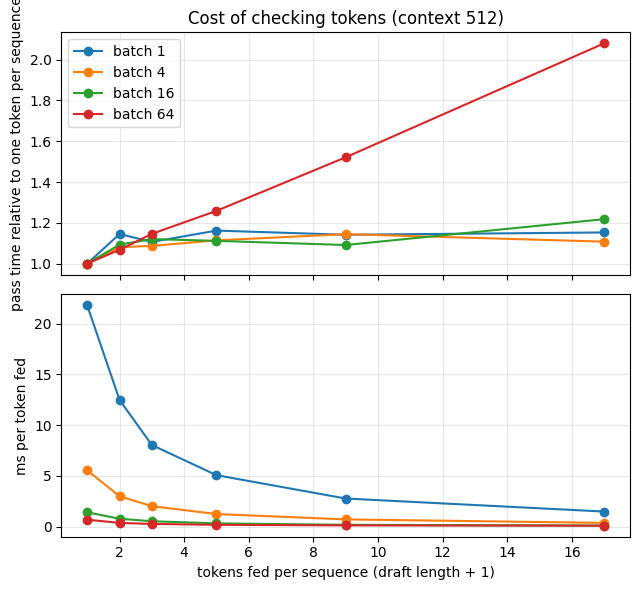

In [33]:
line_groups_stacked(vc_df, "tokens_per_seq", ["rel_to_one_token", "ms_per_token"], "group",
                    f"Cost of checking tokens (context {CONTEXT})",
                    ["pass time relative to one token per sequence", "ms per token fed"],
                    xlabel="tokens fed per sequence (draft length + 1)", zero=False, save="stage6_verify_cost")

**How to read it.**

- **At batch 1 the extra tokens are nearly free.** A pass that checks several drafted tokens costs only slightly more than a one-token step, so one pass that yields two or three tokens is a real saving.
- **The cost per token fed falls steeply at small batch.** Time per token fed is what you pay for each guess. At batch 1 it falls almost in proportion to the tokens fed, which is what "launch-bound" looks like.
- **At large batch the extra tokens are no longer free.** With many sequences each feeding several tokens, the arithmetic is no longer hidden behind the launches and the pass grows with the tokens fed. The gain from speculation therefore shrinks as the batch grows, and at a large enough batch it would vanish. This is the same limit as in Stage 3, seen from the other side.
- Each point is a median of a few passes, so expect some noise.

---
## 5. B. When guessing works

**Goal:** measure how often the draft is right, on three kinds of text.

**Setup.** `copy` prompts hold a passage and ask the model to repeat it. `code` prompts are code that repeats its own pattern, continued in the same style. `open` prompts are free-form writing. For each workload, plain decoding is the baseline and prompt lookup runs with draft lengths `KS`. `MAX_NEW` tokens are generated per prompt.

**Concept.** Prompt lookup can only propose what already appeared in the context. When the model is **copying**, the draft is right almost every time, so a pass yields several tokens. In **repetitive code** it is right often. In **open-ended writing** the prompt offers little to copy, but the lookup also searches the model's own output, and greedy decoding from a small model tends to repeat itself, so matches may appear anyway. We measure rather than assume. Longer drafts help only if the earlier tokens of the draft were right, so acceptance falls and the gain per extra draft token shrinks as `k` grows.

> **Predict:** for which workload does acceptance stay high as `k` grows, and is open-ended text really out of reach?

In [23]:
MAX_NEW = 48 if QUICK else 128
KS = [4] if QUICK else [2, 4, 8]
spec_rows = sweep_speculative(model, PROMPT_IDS, MAX_NEW, KS)
spec_df = pd.DataFrame(spec_rows)
spec_df[["workload", "k", "tok_s", "speedup_x", "tokens_per_step", "acceptance", "draft_found_frac", "step_ms", "n_exact", "n_prompts"]].round(2)

copy   k=2:   91.0 tok/s (1.99x)  2.18 tokens/step  acceptance 0.80  exact False
copy   k=4:  117.4 tok/s (2.57x)  2.84 tokens/step  acceptance 0.71  exact False
copy   k=8:  147.8 tok/s (3.24x)  3.58 tokens/step  acceptance 0.60  exact False
code   k=2:   91.4 tok/s (2.01x)  2.19 tokens/step  acceptance 0.76  exact True
code   k=4:  116.8 tok/s (2.56x)  2.82 tokens/step  acceptance 0.64  exact True
code   k=8:  141.3 tok/s (3.10x)  3.41 tokens/step  acceptance 0.47  exact True
open   k=2:   76.2 tok/s (1.65x)  1.80 tokens/step  acceptance 0.68  exact True
open   k=4:   92.7 tok/s (2.00x)  2.14 tokens/step  acceptance 0.57  exact True
open   k=8:  102.4 tok/s (2.21x)  2.41 tokens/step  acceptance 0.42  exact True


,workload,k,tok_s,speedup_x,tokens_per_step,acceptance,draft_found_frac,step_ms,n_exact,n_prompts
0,copy,0,45.67,1.00,1.00,0.00,0.00,21.89,4,4
1,copy,2,90.98,1.99,2.18,0.80,0.74,23.57,3,4
2,copy,4,117.41,2.57,2.84,0.71,0.66,23.67,3,4
3,copy,8,147.80,3.24,3.58,0.60,0.58,23.56,3,4
4,code,0,45.56,1.00,1.00,0.00,0.00,21.92,4,4
5,code,2,91.41,2.01,2.19,0.76,0.78,23.57,4,4
6,code,4,116.84,2.56,2.82,0.64,0.73,23.65,4,4
7,code,8,141.32,3.10,3.41,0.47,0.67,23.53,4,4
8,open,0,46.27,1.00,1.00,0.00,0.00,21.60,4,4
9,open,2,76.16,1.65,1.80,0.68,0.59,23.36,4,4


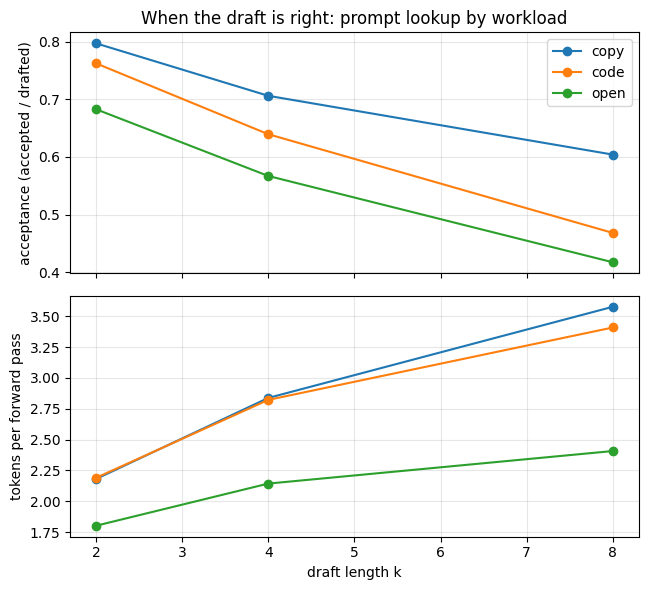

In [34]:
line_groups_stacked(spec_df[spec_df.k > 0], "k", ["acceptance", "tokens_per_step"], "workload",
                    "When the draft is right: prompt lookup by workload",
                    ["acceptance (accepted / drafted)", "tokens per forward pass"],
                    xlabel="draft length k", zero=False, save="stage6_acceptance")

**How to read it.**

- **Copying works best.** Acceptance on `copy` is high, so each pass yields several tokens, and tokens per pass rises with `k`.
- **Repetitive code is close behind.** The draft is found and right for the repeated patterns, and wrong where the pattern changes.
- **Open-ended writing gained too, which we did not expect.** The draft is found in about half of the passes, and when found it is right more than half the time. A likely reason is that the lookup searches the whole context, including the model's own output, and greedy decoding from a small model tends to repeat itself. That is a hypothesis, not something this notebook measures. Expect the gain on open text to depend on the model and on greedy decoding.
- **Acceptance falls as `k` grows,** because a long draft is only accepted up to its first wrong token. Tokens per pass still rises with `k`, but more slowly.
- **`n_exact` counts the prompts whose output equals plain greedy exactly.** A few outputs differ somewhere in the 128 generated tokens. Gate 2 showed that early tokens match, and an fp16 near-tie (a checking pass has a different matrix shape from a one-token step) is the likely cause, but this notebook does not locate where each difference starts.
- Each cell is a single pass over a handful of prompts, so expect some noise.

---
## 6. C. The speedup

**Goal:** turn tokens per pass into time, and see how close the measurement is to what sections 4 and 5 predict.

**Concept.** Speedup is tokens per pass times the ratio of a plain step to a checking pass, minus the overhead outside the forward pass (looking for the draft, comparing tokens, the prefill, which no speculation can speed up):

```
predicted speedup  =  tokens per pass  x  (plain step time / checking pass time)
```

Both factors are measured: tokens per pass in section 5, and the pass times (`step_ms`) in the same table. The measured speedup is lower by the overhead. As a ceiling we also run the **oracle** draft from Gate 4, which is always right: it shows the best a draft of that length could do on this model and this GPU, whatever the text.

> **Predict:** for which workload does speculation give a speedup, and how close does it get to the oracle ceiling?

In [25]:
plain_step = spec_df[spec_df.k == 0].set_index("workload")["step_ms"]
spec_df["predicted_x"] = [r.tokens_per_step * plain_step[r.workload] / r.step_ms if r.k > 0 else 1.0 for r in spec_df.itertuples()]
spec_df["overhead_x"] = spec_df.predicted_x / spec_df.speedup_x           # > 1: time lost outside the forward passes

# the ceiling: a draft that is always right, on the copy prompts
import time
def _timed(fn):
    torch.cuda.synchronize(); t0 = time.perf_counter(); out = fn(); torch.cuda.synchronize()
    return out, time.perf_counter() - t0

oracle_rows = []
ref_prompts = PROMPT_IDS["copy"][:2]
refs = [plain(ids, MAX_NEW + 16) for ids in ref_prompts]
plain_t = sum(_timed(lambda ids=ids: plain(ids, MAX_NEW))[1] for ids in ref_prompts)
for k in KS:
    t_spec = 0.0
    for ids, truth_ in zip(ref_prompts, refs):
        orc = lambda context, kk, ids=ids, truth_=truth_: truth_[len(context) - len(ids):len(context) - len(ids) + kk]
        (out, st), dt = _timed(lambda: generate_speculative(model, ids, MAX_NEW, k=k, proposer=orc))
        t_spec += dt
    oracle_rows.append({"workload": "oracle (always right)", "k": k, "speedup_x": plain_t / t_spec})
oracle_df = pd.DataFrame(oracle_rows)

speed_df = pd.concat([spec_df[["workload", "k", "speedup_x"]], oracle_df])
spec_df[spec_df.k > 0][["workload", "k", "speedup_x", "predicted_x", "overhead_x", "tokens_per_step", "step_ms"]].round(2)

,workload,k,speedup_x,predicted_x,overhead_x,tokens_per_step,step_ms
1,copy,2,1.99,2.02,1.02,2.18,23.57
2,copy,4,2.57,2.62,1.02,2.84,23.67
3,copy,8,3.24,3.32,1.03,3.58,23.56
5,code,2,2.01,2.04,1.01,2.19,23.57
6,code,4,2.56,2.62,1.02,2.82,23.65
7,code,8,3.10,3.18,1.02,3.41,23.53
9,open,2,1.65,1.67,1.01,1.80,23.36
10,open,4,2.00,2.03,1.01,2.14,22.79
11,open,8,2.21,2.25,1.02,2.41,23.13


In [26]:
oracle_df.round(2)

,workload,k,speedup_x
0,oracle (always right),2,2.63
1,oracle (always right),4,4.30
2,oracle (always right),8,7.03


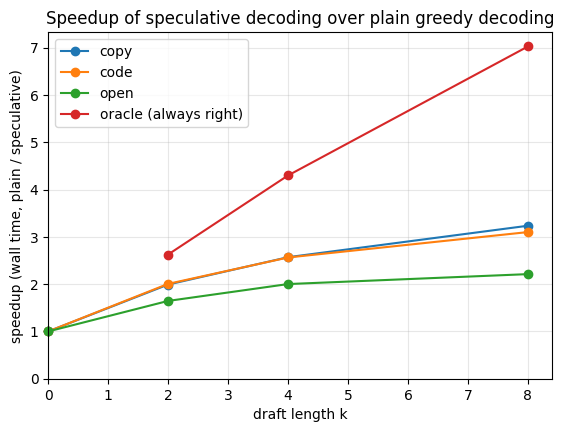

In [27]:
line_groups(speed_df, "k", "speedup_x", "workload", "Speedup of speculative decoding over plain greedy decoding",
            "speedup (wall time, plain / speculative)", xlabel="draft length k", save="stage6_speedup")

**How to read it.**

- **The speedup follows tokens per pass.** The prediction is within a few percent of the measurement, so almost no time is lost outside the forward passes: the prefill and the python search for a draft are small.
- **Copying and repetitive code are about two to three times faster,** and the speedup is still rising at the longest draft tried, with diminishing returns as acceptance falls. The best `k` was not found within this range.
- **The oracle shows the ceiling.** A draft that is always right would do much better at every length, so the limit is the quality of the draft, not the cost of checking it. This is the gap a draft model tries to close, which is the subject of the next stage (exercise 1).
- **Open-ended text pays less but still pays,** for the reason discussed in section 5. A larger model, or sampling, would probably repeat itself less, so do not read this as a general result for free-form text.

---
## 7. D. Under batching: a projection

**Goal:** estimate what happens to the gain when many sequences share each pass, which is how a server runs.

**Concept.** We have not built batched speculation (every sequence accepts a different number of tokens, so the batch becomes ragged, exercise 2), so this section is a **projection**, not a measurement. It combines the two measurements we do have:

```
projected speedup at batch B  =  tokens per pass (section 5)  /  relative cost of a checking pass at batch B (section 4)
```

It assumes every sequence in the batch behaves like the single sequence measured in section 5 (same acceptance, always has a draft), and ignores drafting time and raggedness, so it overstates the real gain. What it shows reliably is the *trend*: how the gain erodes as the batch grows.

In [28]:
proj_rows = []
for r in spec_df[spec_df.k > 0].itertuples():
    t = r.k + 1
    for b in VERIFY_BATCHES:
        cost = vc_df[(vc_df.batch == b) & (vc_df.tokens_per_seq == t)]
        if len(cost):
            proj_rows.append({"workload": r.workload, "k": r.k, "batch": b, "tokens_per_step": r.tokens_per_step,
                              "rel_cost": cost.rel_to_one_token.iloc[0], "projected_x": r.tokens_per_step / cost.rel_to_one_token.iloc[0]})
proj_df = pd.DataFrame(proj_rows)
proj_best = proj_df.loc[proj_df.groupby(["workload", "batch"]).projected_x.idxmax()]       # the best k for each workload and batch
proj_best[["workload", "batch", "k", "tokens_per_step", "rel_cost", "projected_x"]].round(2)

,workload,batch,k,tokens_per_step,rel_cost,projected_x
20,code,1,8,3.41,1.14,2.99
21,code,4,8,3.41,1.14,2.98
22,code,16,8,3.41,1.09,3.12
19,code,64,4,2.82,1.26,2.24
8,copy,1,8,3.58,1.14,3.13
9,copy,4,8,3.58,1.14,3.13
10,copy,16,8,3.58,1.09,3.28
11,copy,64,8,3.58,1.52,2.35
32,open,1,8,2.41,1.14,2.11
33,open,4,8,2.41,1.14,2.10


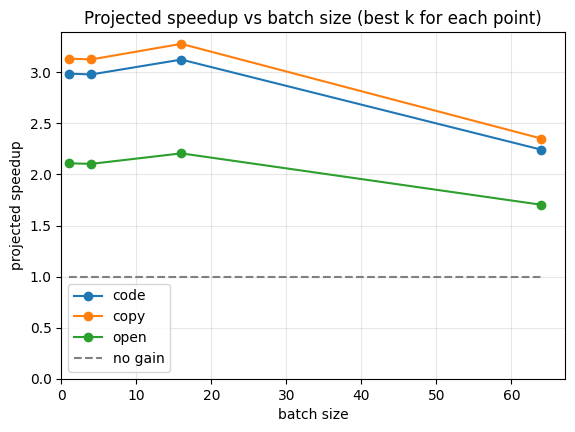

In [29]:
plot_proj = proj_best[["workload", "batch", "projected_x"]].copy()
plot_proj = pd.concat([plot_proj, pd.DataFrame({"workload": "no gain", "batch": VERIFY_BATCHES, "projected_x": 1.0})])
line_groups(plot_proj, "batch", "projected_x", "workload", "Projected speedup vs batch size (best k for each point)",
            "projected speedup", xlabel="batch size", dashed=("no gain",), save="stage6_batch_projection")

**How to read it.**

- **The gain is largest at small batch and erodes at the largest batch tried,** mostly for the long drafts, whose checking pass costs the most there. In this projection it stays above one for every workload throughout the range.
- **Workloads that accept more keep more of their gain.** More tokens per pass pay for a more expensive pass for longer.
- **Speculation and batching compete for the same spare capacity.** A busy server already fills each pass with many sequences, which is the other way to spend idle compute. That makes speculation mainly a latency tool for lightly loaded servers.
- This is a projection built from single-sequence acceptance. It ignores drafting time and the raggedness of a real batch, so read the trend and not the numbers.

---
## 8. Save results

`results/stage6.json` holds everything needed to re-plot without re-running:

- `env` and `config`: GPU, library versions, model revision, and every experiment parameter,
- `verify_cost`: section 4 (pass time vs tokens fed, by batch size),
- `speculative`: section 5 and 6 (plain and speculative decoding by workload and draft length),
- `oracle`: the ceiling (section 6),
- `projection`: section 7.

Final published numbers should come from one consistent environment.

In [30]:
def records(df):
    # JSON has no NaN: missing values become null
    return df.round(4).astype(object).where(pd.notnull(df), None).to_dict(orient="records")

out = {
    "env": {**ENV, "max_pos": MAX_POS},
    "config": {
        "seed": SEED, "quick": QUICK,
        "verify_cost": {"context": CONTEXT, "batches": VERIFY_BATCHES, "tokens_per_seq": VERIFY_TOKENS},
        "speculative": {"max_new": MAX_NEW, "ks": KS, "drafter": "prompt lookup (ngram_max 3, ngram_min 1)",
                        "prompts": {name: len(plist) for name, plist in PROMPT_IDS.items()}},
    },
    "verify_cost": records(vc_df.drop(columns="group")),
    "speculative": records(spec_df),
    "oracle": records(oracle_df),
    "projection": records(proj_df),
}
save_results("results/stage6.json", out)

saved results/stage6.json


### Figure inventory

Every figure was written to `results/` by the cell that produced it. This cell lists them and fails if one is missing.

In [31]:
FIGURES = {
    "stage6_verify_cost.png": "Forward pass time vs tokens fed per sequence, by batch size (section 4)",
    "stage6_acceptance.png": "Acceptance and tokens per pass vs draft length, by workload (section 5)",
    "stage6_speedup.png": "Speedup over plain greedy decoding vs draft length, by workload, with the oracle ceiling (section 6)",
    "stage6_batch_projection.png": "Projected speedup vs batch size from sections 4 and 5 (section 7)",
}
missing = [f for f in FIGURES if not os.path.exists(f"results/{f}")]
assert not missing, f"missing figures: {missing}"
pd.DataFrame({"file": list(FIGURES), "what it shows": list(FIGURES.values())})

,file,what it shows
0,stage6_verify_cost.png,"Forward pass time vs tokens fed per sequence, ..."
1,stage6_acceptance.png,Acceptance and tokens per pass vs draft length...
2,stage6_speedup.png,Speedup over plain greedy decoding vs draft le...
3,stage6_batch_projection.png,Projected speedup vs batch size from sections ...


---
## 9. Publish results (and code, if this is the newest notebook) to GitHub (optional)

Set `PUSH = True` to push this run to your repo. The cell below is identical in every notebook of the series except `PUSH` and `COMMIT_MSG`. It calls `publish()` from `bench/publish.py`, which clones the repo, pulls, copies `results/` in, and copies `minivllm/` and `bench/` in only if this notebook's stage is at least the stage recorded in the repo (`minivllm/STAGE`). It then commits and pushes, printing git's output and raising an error if any git step fails. This is the newest notebook, so it publishes code as well as results. An older notebook rerun later pushes results only and cannot overwrite this code.

It needs a Kaggle secret named `minivllm-github-token` holding a GitHub token with write access. The repo name and git identity are constants at the top of `bench/publish.py`. The token is used only for the clone, pull and push commands and is not stored in the repo's git config.

In [35]:
PUSH = True                              # True: publish to GitHub at the end of the run
COMMIT_MSG = "Stage 6: speculative decoding"   # the only other line that differs between notebooks
FORCE_CODE = False                       # leave False: code is published automatically from the newest stage

if PUSH:
    from kaggle_secrets import UserSecretsClient
    from bench.publish import publish, SECRET_NAME
    publish(token=UserSecretsClient().get_secret(SECRET_NAME), message=COMMIT_MSG, force_code=FORCE_CODE)

Cloning into 'mini-vllm'...
remote: Enumerating objects: 852, done.        
remote: Counting objects: 100% (239/239), done.        
remote: Compressing objects: 100% (194/194), done.        
remote: Total 852 (delta 130), reused 129 (delta 41), pack-reused 613 (from 1)        
Receiving objects: 100% (852/852), 18.25 MiB | 31.41 MiB/s, done.
Resolving deltas: 100% (428/428), done.
Already up to date.
From https://github.com/chizkidd/minivllm
 * branch            HEAD       -> FETCH_HEAD
notebook stage 6, repo code stage 6: publishing code and results
[main 60df4af] Stage 6: speculative decoding
 6 files changed, 741 insertions(+), 1 deletion(-)
 create mode 100644 results/stage6.json
 create mode 100644 results/stage6_acceptance.png
 create mode 100644 results/stage6_batch_projection.png
 create mode 100644 results/stage6_speedup.png
 create mode 100644 results/stage6_verify_cost.png
Enumerating objects: 14, done.
Counting objects: 100% (14/14), done.
Delta compression using up to 4 th

---
## 10. Summary

In [36]:
from IPython.display import Markdown, display

def show_table(rows, headers=("Metric", "Result", "Note")):
    esc = lambda c: str(c).replace("|", "\\|")   # a literal | would break the table
    out_ = ["| " + " | ".join(headers) + " |", "|" + "|".join(["---"] * len(headers)) + "|"]
    for r in rows:
        out_.append("| " + " | ".join([f"**{esc(r[0])}**"] + [esc(c) for c in r[1:]]) + " |")
    display(Markdown("\n".join(out_)))

k_ref = 4 if 4 in KS else KS[0]
sp = {w: spec_df[(spec_df.workload == w) & (spec_df.k == k_ref)].iloc[0] for w in PROMPT_IDS}
v1 = vc_df[(vc_df.batch == 1) & (vc_df.tokens_per_seq == k_ref + 1)].iloc[0]
vb = vc_df[(vc_df.batch == max(VERIFY_BATCHES)) & (vc_df.tokens_per_seq == k_ref + 1)].iloc[0]
orc = oracle_df[oracle_df.k == k_ref].iloc[0]
pb = proj_best[(proj_best.workload == "copy") & (proj_best.batch == max(VERIFY_BATCHES))].iloc[0]

show_table([
    (f"Cost of checking k = {k_ref} drafted tokens at batch 1",
     f"{v1.rel_to_one_token:.2f}x a one-token step", f"{v1.ms:.1f} ms for {k_ref + 1} tokens"),
    (f"The same pass at batch {max(VERIFY_BATCHES)}",
     f"{vb.rel_to_one_token:.2f}x a one-token step", "extra tokens stop being free"),
    (f"Copy workload, k = {k_ref}",
     f"{sp['copy'].tokens_per_step:.2f} tokens per pass, acceptance {sp['copy'].acceptance:.2f}",
     f"speedup {sp['copy'].speedup_x:.2f}x, oracle ceiling {orc.speedup_x:.2f}x"),
    (f"Code workload, k = {k_ref}",
     f"{sp['code'].tokens_per_step:.2f} tokens per pass, acceptance {sp['code'].acceptance:.2f}", f"speedup {sp['code'].speedup_x:.2f}x"),
    (f"Open workload, k = {k_ref}",
     f"{sp['open'].tokens_per_step:.2f} tokens per pass, draft found in {100 * sp['open'].draft_found_frac:.0f}% of passes",
     f"speedup {sp['open'].speedup_x:.2f}x"),
    (f"Copy workload projected to batch {max(VERIFY_BATCHES)}",
     f"{pb.projected_x:.2f}x at the best k ({int(pb.k)})", "a projection, not a measurement"),
    ("Exactness", f"{int(spec_df[spec_df.k > 0].n_exact.sum())} of {int(spec_df[spec_df.k > 0].n_prompts.sum())} outputs identical to plain greedy",
     "the rest differ only after a late fp16 near-tie"),
])

| Metric | Result | Note |
|---|---|---|
| **Cost of checking k = 4 drafted tokens at batch 1** | 1.16x a one-token step | 25.3 ms for 5 tokens |
| **The same pass at batch 64** | 1.26x a one-token step | extra tokens stop being free |
| **Copy workload, k = 4** | 2.84 tokens per pass, acceptance 0.71 | speedup 2.57x, oracle ceiling 4.30x |
| **Code workload, k = 4** | 2.82 tokens per pass, acceptance 0.64 | speedup 2.56x |
| **Open workload, k = 4** | 2.14 tokens per pass, draft found in 52% of passes | speedup 2.00x |
| **Copy workload projected to batch 64** | 2.35x at the best k (8) | a projection, not a measurement |
| **Exactness** | 33 of 36 outputs identical to plain greedy | the rest differ only after a late fp16 near-tie |

### What we learned

#### Questions

- **Why is checking several tokens cheap?** (Section 4: forward pass time vs tokens fed per sequence.)
- **When is a guess right?** (Section 5: acceptance and tokens per pass by workload and draft length.)
- **What does it buy in time?** (Section 6: measured vs predicted speedup, and the ceiling.)
- **Does it survive batching?** (Section 7: a projection from sections 4 and 5.)

#### Answers

- **Checking several tokens is cheap while the step is launch-bound.** At small batch a pass that checks a draft costs only a little more than a one-token step, and the extra does not grow with the number of tokens. At a large batch the step is already heavier and extra tokens stop being free.
- **A guess is right when the output repeats the context.** Copying and repetitive code accept the most, acceptance falls as the draft gets longer, and open-ended writing also gained, probably because a small greedy model repeats itself.
- **It buys about two to three times on repetitive text.** The speedup is close to what tokens per pass and the pass cost predict, and a perfect draft would do much better, so the limit is the draft.
- **Under batching the projected gain erodes for long drafts but stays above one.** Speculation competes with batching for spare compute, so it is mainly a latency tool for light load.

### Next: Stage 7, a draft model

Prompt lookup can only repeat what is already in the context. The next stage, [`06_draft_model_speculation.ipynb`](https://github.com/chizkidd/minivllm/blob/main/06_draft_model_speculation.ipynb), keeps the checking pass exactly as it is and replaces the guesser with a small draft model of the same family, so the guesses can be new text. The price is that the draft has to run once per guessed token, so the question becomes how cheap a draft step is next to a target step, and the stage compares the two guessers head to head on the same prompts.

### Exercises

1. **A draft model.** This is now the next stage: [`06_draft_model_speculation.ipynb`](https://github.com/chizkidd/minivllm/blob/main/06_draft_model_speculation.ipynb) uses `Qwen/Qwen2.5-0.5B` to draft for larger models of the same family and measures how cheap the draft has to be for speculation to win.
2. **Batched speculation.** Run speculative decoding inside the continuous or paged scheduler. Each sequence accepts a different number of tokens per pass, so the batch is ragged: what has to change in the decode view and the mask? Compare the measured speedup with the projection of section 7.
3. **Speculative sampling (moved).** Accepting a draft token with probability `min(1, p_target / p_draft)` needs the draft's probabilities, which an n-gram lookup does not have, so this exercise now lives in notebook 06 (Stage 7).
4. **More than one guess.** Propose the continuations of the two most recent matches and check both in one pass with a tree-shaped mask. When does it beat a single, longer draft?
5. **Tune the lookup.** Sweep `ngram_max` and `ngram_min`. Does a longer required match raise acceptance, and at what cost in how often a draft is found?

### References

- Leviathan et al., *Fast Inference from Transformers via Speculative Decoding*: https://arxiv.org/abs/2211.17192
- Chen et al., *Accelerating Large Language Model Decoding with Speculative Sampling*: https://arxiv.org/abs/2302.01318
- Saxena, *Prompt Lookup Decoding*: https://github.com/apoorvumang/prompt-lookup-decoding
- Kwon et al., *Efficient Memory Management for LLM Serving with PagedAttention* (vLLM): https://arxiv.org/abs/2309.06180

---

# Appendix

Refer to the simple examples below to understand how prompt lookup and one checking pass work.

## A.1. Prompt lookup by hand

In [37]:
text = "the cat sat on the mat and the cat"
ctx = tok(text).input_ids
lookup = PromptLookup(ngram_max=3, ngram_min=1)
draft = lookup(ctx, 4)
print("context: ", [tok.decode([t]) for t in ctx])
print("draft:   ", [tok.decode([t]) for t in draft], "<- what followed the most recent earlier occurrence of the last tokens")

for n in (3, 2, 1):
    tail = ctx[-n:]
    hit = [i for i in range(len(ctx) - n - 1, -1, -1) if ctx[i:i + n] == tail]
    print(f"last {n} token(s) {[tok.decode([t]) for t in tail]}: earlier occurrence starts at index {hit[0] if hit else None}")

context:  ['the', ' cat', ' sat', ' on', ' the', ' mat', ' and', ' the', ' cat']
draft:    [' sat', ' on', ' the', ' mat'] <- what followed the most recent earlier occurrence of the last tokens
last 3 token(s) [' and', ' the', ' cat']: earlier occurrence starts at index None
last 2 token(s) [' the', ' cat']: earlier occurrence starts at index None
last 1 token(s) [' cat']: earlier occurrence starts at index 1


## A.2. One checking pass, step by step

The model has already written the beginning of an exact copy. We take the next draft from prompt lookup, check it in one pass, and show what was accepted, what the model would have chosen after each fed token, and what the cache keeps.

In [38]:
ids = PROMPT_IDS["copy"][0]
head = plain(ids, 12)                                    # the first 12 tokens of the copy, from plain decoding
context = ids + head
draft = PromptLookup()(context, 4)

cache = KVCache(model.n_layers, 1, model.n_kv, len(context) + 8, model.hd, device, model.dtype)
model.forward(torch.tensor([context[:-1]], device=device), cache)         # the cache holds everything except the last token
n0 = cache.length
feed = torch.tensor([[context[-1]] + draft], device=device)
mask = (torch.arange(n0 + feed.shape[1], device=device)[None, :]
        <= (n0 + torch.arange(feed.shape[1], device=device))[:, None])[None, None]
choice = model.forward(feed, cache, attn_mask=mask, all_logits=True).argmax(-1)[0].tolist()

a = 0
while a < len(draft) and choice[a] == draft[a]:
    a += 1
show = lambda xs: [tok.decode([t]) for t in xs]
print("fed:                ", show([context[-1]] + draft))
print("model's choice after each:", show(choice))
print(f"accepted {a} of {len(draft)} drafted tokens -> tokens produced by this pass: {show(choice[:a + 1])}")
print(f"cache length after the pass: {cache.length} (= {n0} + {feed.shape[1]} fed)")
cache.truncate(n0 + a + 1)
print(f"after truncate: {cache.length} (= {n0} + {a} accepted + 1 for the last fed token); the {len(draft) - a} rejected keys are forgotten")

fed:                 [' of', ' a', ' narrow', ' river', '.']
model's choice after each: [' a', ' narrow', ' river', '.', ' Every']
accepted 4 of 4 drafted tokens -> tokens produced by this pass: [' a', ' narrow', ' river', '.', ' Every']
cache length after the pass: 138 (= 133 + 5 fed)
after truncate: 138 (= 133 + 4 accepted + 1 for the last fed token); the 0 rejected keys are forgotten
